<div style="background:#2f7d58;color:white;padding:22px 26px;border-radius:12px;">
<h1 style="margin:0;color:white;">Project · Exploratory Data Analysis</h1>
<h2 style="margin:8px 0 0 0;color:white;font-weight:500;">Speed Dating Experiment — understanding the data before modeling</h2>
</div>

**Course:** Recommender Systems — Master Applied Data Science and AI
**Project:** A reciprocal recommender system for speed dating
**Authors:** Barnard Alison · Kohler Andrin · Tabalae Petronela · Sever Alin (HSLU)
**Dataset:** Speed Dating Experiment (Fisman & Iyengar, Columbia University, 2002–2004)
**Data file:** `Data/Speed_Dating_Data.csv` (Latin-1), read from the project folder — no download step

> **How to run.** Python 3.11 with `pip install -r requirements.txt`. Open from the **repository
> root** (the data path is relative) and run top to bottom; the notebook is deterministic given
> `SEED = 42`. Full execution takes roughly two minutes — Section 15 fits a clustering model and 42
> gradient-boosted trees. **Next notebook:** `02_Speed_Dating_Feature_Engineering.ipynb`.

## What this notebook does

Before we build any recommender, we look at the *shape* of the data. This notebook answers the
practical questions that directly affect how we design and evaluate the model:

1. **Wave (session) sizes** — how big is each event? This is the unit we will split on.
2. **Match rate** — how often do two people match? This tells us about class imbalance.
3. **Partners per participant** — how many candidates does each person rank? This sets our top-$K$ cut-offs.
4. **Missing-data map** — which columns are usable, and which are mostly empty?
5. **Who is in the room** — the race, gender and demographic make-up, and what it allows us to claim
   about fairness.
6. **How concentrated is desirability** — our popularity *baseline*, examined directly: its distribution
   by gender, who the most-wanted participants are, and how unequally attention is shared.
7. **Is the evaluation protocol viable** — do users have relevant items to find, and are the 21 waves
   comparable enough to average over?
8. **Do the intended features carry signal** — including the stated-vs-observed preference gap that
   the compatibility-gap features and the gender-asymmetric clustering are built on.
9. **Which features survive the pre-date constraint** — the proposal only admits signals available
   *before* the date, so we measure that block separately from the in-date scorecard ratings.
10. **What scales are the variables on** — the range, out-of-range and cardinality audit that the
    normalisation step in the next notebook is built from.
11. **Does the evaluation protocol permit the features we want** — leave-one-wave-out CV makes every
    test fold a genuine cold start, which turns out to rule out a whole family of features and to
    break the popularity baseline as currently worded.

> **Sources.** `dataset_key_description.qmd` is the authoritative dictionary for all 195 columns —
> every column used here has been audited against it.
>
> **The proposal deck (`reciprocal_rs_slide.pptx`) is the specification this notebook answers to.**
> Slide 4 fixes the baseline (**Z** popularity), the two methods (**X₁** cluster-based, **X₂**
> factorization machine) and the harmonic-mean reciprocal aggregation; slide 5 fixes the protocol
> (leave-one-wave-out, 21 folds), the relevance label (**mutual match**), the rule that **features
> are strictly pre-date**, and the four metrics (**NDCG@3, Precision@3, MRR, Coverage@3**).

Every step has a short explanation of *why* we do it and *what to notice*.

## 1. Setup

We use only standard scientific-Python libraries, exactly as in the course labs. We fix a random seed so the notebook is reproducible.

In [1]:
# Project dependencies.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Reproducibility: any randomness in the notebook uses this seed.
SEED = 42
rng = np.random.default_rng(SEED)

# Nicer display defaults for wide tables.
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("NumPy :", np.__version__)
print("pandas:", pd.__version__)

NumPy : 1.26.4
pandas: 3.0.5


## 2. Load the Speed Dating data

The dataset is stored at `Data/Speed_Dating_Data.csv`. It uses Latin-1 encoding.

In [2]:
csv_path = Path("Data") / "Speed_Dating_Data.csv"
df = pd.read_csv(csv_path, encoding="latin-1")

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns.")

Loaded 8,378 rows and 195 columns.


## 3. Understand the structure — one row is one *date*

Each **row is a single 4-minute date, seen from one participant's point of view**. Because both
people record the date, every meeting appears **twice** (once from each side). The columns that
encode the relationships are:

| Column | Meaning |
|---|---|
| `iid` | the participant (global id — unique per person) |
| `pid` | the partner's `iid` for this date (**who they dated**) |
| `wave` | the event / session number, 1–21 (**which session**) |
| `dec` | this participant's yes/no decision about the partner |
| `dec_o` | the partner's yes/no decision about this participant |
| `match` | 1 if **both** said yes, else 0 — our target label |

So `(iid, pid)` tells us who dated whom, and `wave` tells us in which session.

In [3]:
# A first look at the key relationship columns.
key_cols = ["iid", "pid", "wave", "gender", "dec", "dec_o", "match"]
display(df[key_cols].head(8))

# Confirm the three facts we rely on for the project.
n_participants = df["iid"].nunique()
n_waves        = df["wave"].nunique()
one_wave_per_person = df.groupby("iid")["wave"].nunique().max() == 1

print(f"Participants (unique iid): {n_participants}")
print(f"Waves / sessions:          {n_waves}")
print(f"Each person is in exactly one wave: {one_wave_per_person}")

,iid,pid,wave,gender,dec,dec_o,match
0,1,11.000,1,0,1,0,0
1,1,12.000,1,0,1,0,0
2,1,13.000,1,0,1,1,1
3,1,14.000,1,0,1,1,1
4,1,15.000,1,0,1,1,1
5,1,16.000,1,0,0,1,0
6,1,17.000,1,0,1,0,0
7,1,18.000,1,0,0,0,0


Participants (unique iid): 551
Waves / sessions:          21
Each person is in exactly one wave: True


### Every date stays inside one session

For the split to be leakage-free we need each date to belong to a single wave (no cross-session
dates). We verify this by joining the table to itself on `iid ↔ pid` and checking both sides
share the same wave.

In [4]:
# Join each date to its exact MIRROR row (the same meeting from the partner's side).
# The mirror of (iid=a, pid=b) is the row with (iid=b, pid=a), so we match on both keys.
merged = df.merge(
    df,
    left_on=["iid", "pid"],
    right_on=["pid", "iid"],
    suffixes=("", "_partner"),
)
print(f"{len(merged):,} of {len(df):,} dates have their mirror row present.")

# Both people are always in the same wave.
dates_within_one_wave = (merged["wave"] == merged["wave_partner"]).all()
print("Every matched date is within a single wave:", dates_within_one_wave)

# Reciprocal structure: the partner's own 'dec' should equal our 'dec_o'.
reciprocity_ok = (merged["dec_partner"] == merged["dec_o"]).mean()
print(f"Rows where partner's dec == our dec_o: {reciprocity_ok:.1%}")

# One more integrity check, from the data key: `round` records how many people each participant
# was scheduled to meet. It should equal the number of rows they have.
scheduled = df.drop_duplicates("iid").set_index("iid")["round"]
observed  = df.groupby("iid").size()
short = (scheduled - observed)
print(f"\nParticipants whose `round` != their row count: {int((short != 0).sum())} of {len(short)} "
      f"(all short by {int(short[short != 0].unique()[0])} row)")

8,368 of 8,378 dates have their mirror row present.
Every matched date is within a single wave: True
Rows where partner's dec == our dec_o: 100.0%

Participants whose `round` != their row count: 14 of 551 (all short by 1 row)


**What to notice:** both checks pass. This is exactly why we can split by `wave` — holding out a whole session removes those people *and* their mirror rows together, with no leakage.

## 4. Wave (session) sizes

Each wave is one speed-dating event. Since we plan to cross-validate by **holding out a whole wave
at a time**, we need to know how many people and how many dates each wave contains — a fold that is
too small would give unstable metrics.

In [5]:
# People per wave and dates (rows) per wave.
people_per_wave = df.groupby("wave")["iid"].nunique()
dates_per_wave  = df.groupby("wave").size()

wave_summary = pd.DataFrame({
    "participants": people_per_wave,
    "dates_rows": dates_per_wave,
}).reset_index()

display(wave_summary)
print(f"Participants per wave — min {people_per_wave.min()}, "
      f"median {int(people_per_wave.median())}, max {people_per_wave.max()}")

,wave,participants,dates_rows
0,1,20,200
1,2,35,608
2,3,20,200
3,4,36,648
4,5,19,190
5,6,10,50
6,7,32,512
7,8,20,200
8,9,40,800
9,10,18,162


Participants per wave — min 10, median 24, max 44


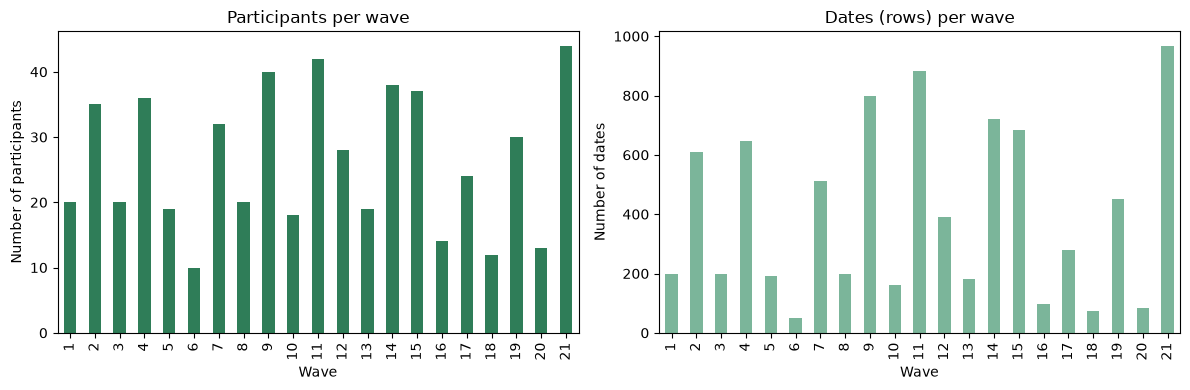

In [6]:
# Visualise the two together.
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

people_per_wave.plot(kind="bar", ax=ax[0], color="#2f7d58")
ax[0].set_title("Participants per wave")
ax[0].set_xlabel("Wave"); ax[0].set_ylabel("Number of participants")

dates_per_wave.plot(kind="bar", ax=ax[1], color="#7bb59a")
ax[1].set_title("Dates (rows) per wave")
ax[1].set_xlabel("Wave"); ax[1].set_ylabel("Number of dates")

plt.tight_layout(); plt.show()

**What to notice:** wave sizes vary quite a lot. A few small waves may be too thin to evaluate on their own — if so, the fallback is leave-one-*participant*-out. Note this when we design the split.

## 5. Match rate and decision rates

A **match** needs *both* people to say yes, so matches are much rarer than one-sided "yes" decisions.
Knowing this rate matters because a rare positive class means plain accuracy is misleading — we must
evaluate with ranking / minority-class metrics instead.

In [7]:
# Overall rates. Each row carries this participant's decision (dec),
# the partner's decision (dec_o), and the symmetric match label.
overall = pd.Series({
    "P(dec = yes)   one-sided": df["dec"].mean(),
    "P(dec_o = yes) partner":   df["dec_o"].mean(),
    "P(match = 1)   mutual":    df["match"].mean(),
})
display(overall.to_frame("rate"))

print(f"About {df['match'].mean():.1%} of dates end in a mutual match, "
      f"versus {df['dec'].mean():.1%} one-sided 'yes' decisions.")

,rate
P(dec = yes) one-sided,0.420
P(dec_o = yes) partner,0.420
P(match = 1) mutual,0.165


About 16.5% of dates end in a mutual match, versus 42.0% one-sided 'yes' decisions.


### Does the yes-rate differ by gender?

A classic finding in this dataset is that acceptance rates differ between men and women. We check it
because a gender gap is relevant both to modeling and to the fairness metric in our proposal
(`gender = 0` is female, `1` is male).

,n_dates,yes_rate,match_rate
gender,,,
female,4184,0.365,0.165
male,4194,0.474,0.165


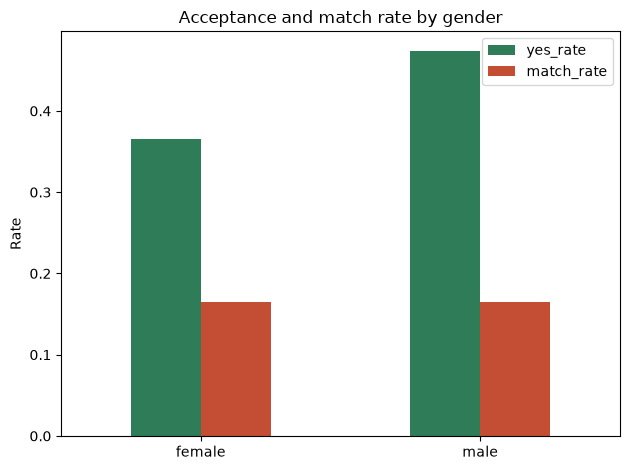

In [8]:
# Decision and match rate split by the decider's gender.
by_gender = df.groupby("gender").agg(
    n_dates=("match", "size"),
    yes_rate=("dec", "mean"),
    match_rate=("match", "mean"),
).rename(index={0: "female", 1: "male"})
display(by_gender)

ax = by_gender[["yes_rate", "match_rate"]].plot(kind="bar", color=["#2f7d58", "#c44e34"])
ax.set_title("Acceptance and match rate by gender")
ax.set_xlabel(""); ax.set_ylabel("Rate"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

**What to notice:** two things.

**Matches are rare.** 16.5% of dates end in a mutual match, against 42.0% one-sided "yes"
decisions. This **class imbalance** is why our proposal evaluates ranking metrics (NDCG,
Precision@K) rather than accuracy.

**The gender gap is real and sizeable.** Men say yes to **47.4%** of the partners they meet, women
to **36.5%** — a gap of **10.9 percentage points**. Because this is a gap in who *gives* a yes, a
model that ignores the decider's gender will be systematically miscalibrated for one of them.

One caveat on the table above: the `match_rate` column is **the same for both genders by
construction**, not by coincidence. `match` is symmetric and every date is recorded from both
sides, so the two groups are averaging over the very same matched dates; the rates differ only in
the fourth decimal, because of the handful of rows with a missing `pid` (Section 9). Only the
`yes_rate` column carries information here.


## 6. Partners per participant (candidate-set size)

In our recommender framing, each participant's **candidate set** is the group of partners they met in
their wave. The number of dates a person had therefore equals how many candidates we rank for them —
which directly determines sensible top-$K$ cut-offs.

,partners_per_participant
count,551.000
mean,15.205
std,5.014
min,5.000
25%,10.000
50%,16.000
75%,20.000
max,22.000


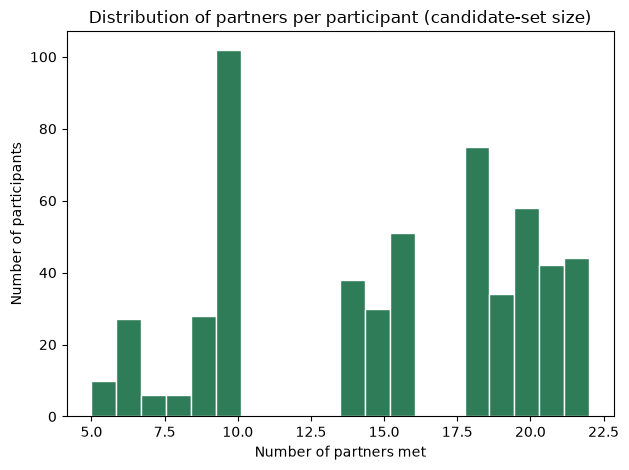

Candidate sets range from 5 to 22 partners (median 16).


In [9]:
# Number of partners each participant met = number of their rows.
partners_per_person = df.groupby("iid").size()

display(partners_per_person.describe().to_frame("partners_per_participant"))

ax = partners_per_person.plot(kind="hist", bins=20, color="#2f7d58", edgecolor="white")
ax.set_title("Distribution of partners per participant (candidate-set size)")
ax.set_xlabel("Number of partners met"); ax.set_ylabel("Number of participants")
plt.tight_layout(); plt.show()

print(f"Candidate sets range from {partners_per_person.min()} to {partners_per_person.max()} partners "
      f"(median {int(partners_per_person.median())}).")

**What to notice:** most people meet only ~10–20 partners. Because the lists are short, `@10` is often close to the whole list — which is why the proposal cuts at **@3** (NDCG@3, Precision@3, Coverage@3) and adds **MRR**, which is uncut and so still sees reordering below rank 3.

## 7. Missing-data map

Real survey data has gaps. We check missingness for two groups of columns:

- the **core modeling columns** we intend to use (ids, decisions, the six attribute ratings); these
  must be mostly complete;
- the **worst offenders** overall, so we know which columns to avoid.

In [10]:
# Missing fraction per column, sorted.
missing_frac = df.isna().mean().sort_values(ascending=False)

# (a) Core columns we plan to use in the recommender.
core_cols = ["iid", "pid", "wave", "gender", "dec", "dec_o", "match",
             "attr", "sinc", "intel", "fun", "amb", "shar",
             "attr_o", "sinc_o", "intel_o", "fun_o", "amb_o", "shar_o", "int_corr"]
core_missing = missing_frac.reindex(core_cols)
display(core_missing.to_frame("missing_fraction"))

,missing_fraction
iid,0.000
pid,0.001
wave,0.000
gender,0.000
dec,0.000
dec_o,0.000
match,0.000
attr,0.024
sinc,0.033
intel,0.035


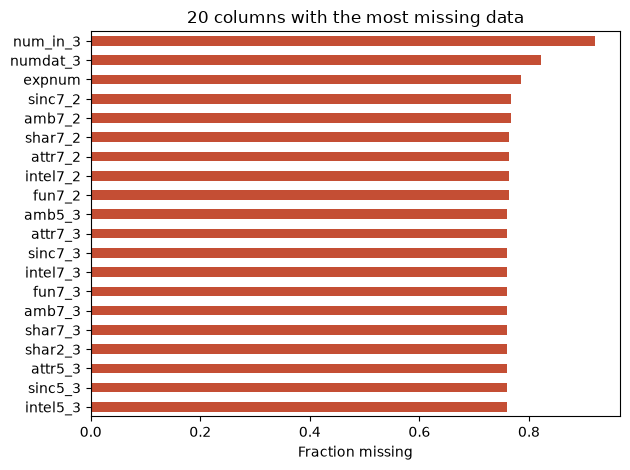

59 of 195 columns are more than 50% empty.


In [11]:
# (b) The 20 columns with the most missing data (usually follow-up survey fields).
worst = missing_frac.head(20)

ax = worst.iloc[::-1].plot(kind="barh", color="#c44e34")
ax.set_title("20 columns with the most missing data")
ax.set_xlabel("Fraction missing"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

print(f"{(missing_frac > 0.5).sum()} of {df.shape[1]} columns are more than 50% empty.")


**What to notice:** the ids, decisions and `match` label are essentially complete, and the six
attribute ratings have only minor gaps — good news for the model. The heavily-missing columns are
mostly the day-after and 3-week follow-up surveys (`*_2`, `*_3`, `*_s`), which we do not need.

A practical point about the *stated-preference* blocks. The data key warns that these were recorded
on **different scales across waves** — a 100-point allocation in most waves, a 1–10 importance
rating in waves 6–9. We test that claim block by block in Section 12, and the answer is **half yes**:

- The block this project uses, `attr1_1 … shar1_1`, is on the 100-point scale in **all 21 waves**.
  Waves 6–9 were collected on the 1–10 scale and have **already been converted to shares for us** —
  which is why they are the only waves whose values are not whole numbers (`16.67`, `12.77`), and
  why those decimals invert exactly back to integer 1–10 answers.
- The raw 1–10 scale **does survive elsewhere**: in `attr4_1 … shar4_1` (and `*4_2`, `*4_3`) for
  waves 6–9, and — undocumented — in `attr1_s … shar1_s` for waves **18–20**, where the key blames
  waves 6–9 instead.

So nothing needs rescaling for what we do here, but anything downstream that reaches for the `4_1`
or `1_s` blocks must rescale first. We still normalise `1_1` to shares, for the small deviations
from exactly 100 that do exist.


### 7.1 The pre-date columns we exclude for missingness

The proposal's data-understanding section asks specifically for *"missingness handling for
income/SAT/etc."* Those columns are all **pre-date** — so the leakage rule does not exclude them,
and they need a decision of their own rather than silence.

In [12]:
# Pre-date profile columns that are admissible but poorly populated.
SPARSE = ["expnum", "mn_sat", "tuition", "income", "exphappy"]
people_all = df.drop_duplicates("iid").set_index("iid")

sparse_audit = pd.DataFrame({
    "missing_fraction": people_all[SPARSE].isna().mean(),
    "participants_with_value": people_all[SPARSE].notna().sum(),
}).sort_values("missing_fraction", ascending=False)
display(sparse_audit)

print("DECISION: exclude `expnum`, `mn_sat`, `tuition` and `income`.")
print("At 49-77% missing, using them means either dropping half the participants or imputing")
print("more than half the column -- and the missingness is not random (income and SAT are blank")
print("for anyone who studied abroad or left the field empty), so an imputed value would carry")
print("its own bias into a fairness analysis.")
print()
print("KEEP `exphappy` -- how happy the participant expects to be with the people they meet (1-10),")
print(f"missing for only {people_all['exphappy'].isna().mean():.1%} of participants. It is a pre-date")
print("self-assessment, which is worth noting given that Section 15 rules out the behavioural")
print("desirability features entirely.")

,missing_fraction,participants_with_value
expnum,0.771,126
mn_sat,0.633,202
tuition,0.575,234
income,0.490,281
exphappy,0.015,543


DECISION: exclude `expnum`, `mn_sat`, `tuition` and `income`.
At 49-77% missing, using them means either dropping half the participants or imputing
more than half the column -- and the missingness is not random (income and SAT are blank
for anyone who studied abroad or left the field empty), so an imputed value would carry
its own bias into a fairness analysis.

KEEP `exphappy` -- how happy the participant expects to be with the people they meet (1-10),
missing for only 1.5% of participants. It is a pre-date
self-assessment, which is worth noting given that Section 15 rules out the behavioural
desirability features entirely.


## 8. Who is in the room — race, gender and demographics

Before we rank anyone, it is worth knowing *who took part*. Two reasons this matters for the project:

- The dataset carries race as side information (`race`, `race_o`, `samerace`, `imprace`), so it is a
  candidate feature for the directional preference model.
- Any **fairness** claim we make is only as strong as the group sizes behind it. If a group has a
  handful of people, a per-group metric is noise.

`race` is coded 1–6; we map the codes to readable labels using the data key.

In [13]:
# Code -> label lookups from the data key (Native American, code 5, is absent from this file).
RACE_LABELS = {
    1: "Black / African American",
    2: "European / Caucasian",
    3: "Latino / Hispanic",
    4: "Asian / Pacific Islander",
    5: "Native American",
    6: "Other",
}
GENDER_LABELS = {0: "female", 1: "male"}

# The CSV is one row per DATE, so a person appears many times. De-duplicate on `iid`
# to get one row per PERSON. This `people` table is reused throughout the rest of the notebook.
people = df.drop_duplicates("iid").set_index("iid")[
    ["gender", "wave", "age", "race", "field_cd", "goal", "imprace", "imprelig"]
].copy()
people["race_label"]   = people["race"].map(RACE_LABELS).fillna("Unknown")
people["gender_label"] = people["gender"].map(GENDER_LABELS)

print(f"{len(people)} unique participants (one row each).")
display(people.head())

551 unique participants (one row each).


,gender,wave,age,race,field_cd,goal,imprace,imprelig,race_label,gender_label
iid,,,,,,,,,,
1,0,1,21.000,4.000,1.000,2.000,2.000,4.000,Asian / Pacific Islander,female
2,0,1,24.000,2.000,1.000,1.000,2.000,5.000,European / Caucasian,female
3,0,1,25.000,2.000,2.000,6.000,8.000,4.000,European / Caucasian,female
4,0,1,23.000,2.000,1.000,1.000,1.000,1.000,European / Caucasian,female
5,0,1,21.000,2.000,1.000,2.000,8.000,1.000,European / Caucasian,female


,participants,share
race_label,,
European / Caucasian,304,0.552
Asian / Pacific Islander,136,0.247
Latino / Hispanic,42,0.076
Other,37,0.067
Black / African American,26,0.047
Unknown,6,0.011


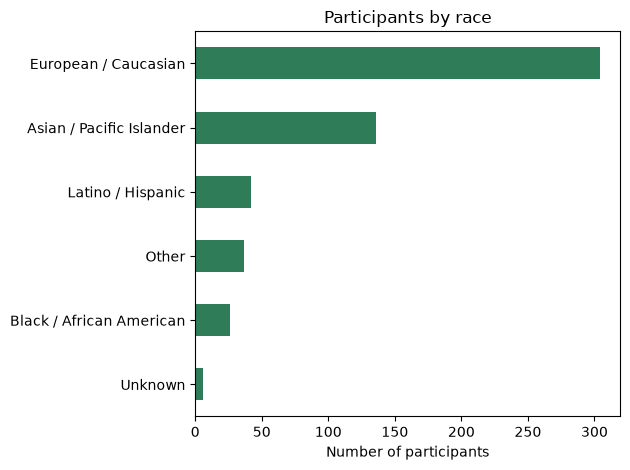

Most common group: European / Caucasian — 304 people (55.2% of the sample).


In [14]:
# Race distribution across participants.
race_counts = people["race_label"].value_counts()
race_table = pd.DataFrame({
    "participants": race_counts,
    "share": race_counts / len(people),
})
display(race_table)

ax = race_counts.sort_values().plot(kind="barh", color="#2f7d58")
ax.set_title("Participants by race")
ax.set_xlabel("Number of participants"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

top_race = race_counts.index[0]
print(f"Most common group: {top_race} — {race_counts.iloc[0]} people "
      f"({race_counts.iloc[0] / len(people):.1%} of the sample).")

gender_label,female,male
race_label,,
Asian / Pacific Islander,71,65
Black / African American,16,10
European / Caucasian,142,162
Latino / Hispanic,25,17
Other,16,21
Unknown,4,2


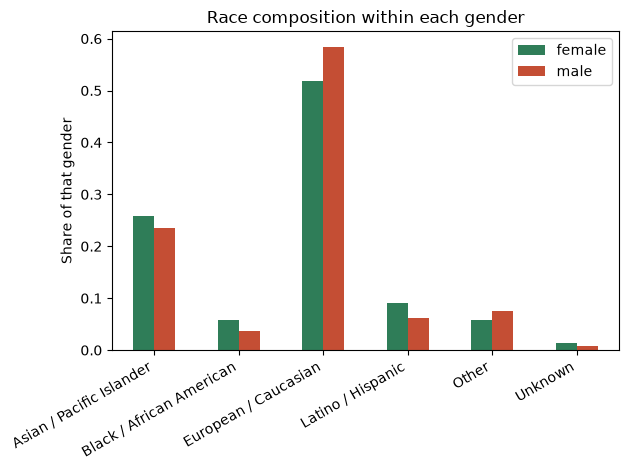

In [15]:
# Race by gender: counts, and the share WITHIN each gender (columns sum to 1).
race_by_gender = pd.crosstab(people["race_label"], people["gender_label"])
display(race_by_gender)

race_shares = pd.crosstab(people["race_label"], people["gender_label"], normalize="columns")
ax = race_shares.plot(kind="bar", color=["#2f7d58", "#c44e34"])
ax.set_title("Race composition within each gender")
ax.set_xlabel(""); ax.set_ylabel("Share of that gender")
plt.xticks(rotation=30, ha="right"); plt.legend(title="")
plt.tight_layout(); plt.show()

In [16]:
# How much does race actually matter to the participants, and to their decisions?
race_lab   = df["race"].map(RACE_LABELS).fillna("Unknown")     # decider's race, per date row
race_o_lab = df["race_o"].map(RACE_LABELS).fillna("Unknown")   # partner's race, per date row

print(f"Dates between two people of the same race: {df['samerace'].mean():.1%}")
print(f"Match rate — same race {df.loc[df['samerace'] == 1, 'match'].mean():.1%} "
      f"vs different race {df.loc[df['samerace'] == 0, 'match'].mean():.1%}")

# Stated importance of same race / religion, and the one-sided yes-rate, per race group.
race_context = pd.DataFrame({
    "participants":   people.groupby("race_label").size(),
    "mean_imprace":   people.groupby("race_label")["imprace"].mean(),
    "mean_imprelig":  people.groupby("race_label")["imprelig"].mean(),
    "yes_rate_given": df.groupby(race_lab)["dec"].mean(),
})
display(race_context)

print("\nMean importance of same race (1-10), by gender:")
display(people.groupby("gender_label")["imprace"].mean().to_frame("mean_imprace"))

Dates between two people of the same race: 39.6%
Match rate — same race 17.1% vs different race 16.1%


,participants,mean_imprace,mean_imprelig,yes_rate_given
Asian / Pacific Islander,136,3.382,3.037,0.461
Black / African American,26,3.462,3.077,0.507
European / Caucasian,304,4.165,3.934,0.390
Latino / Hispanic,42,2.667,3.262,0.405
Other,37,2.892,3.432,0.496
Unknown,6,NaN,NaN,0.317



Mean importance of same race (1-10), by gender:


,mean_imprace
gender_label,
female,4.115
male,3.360


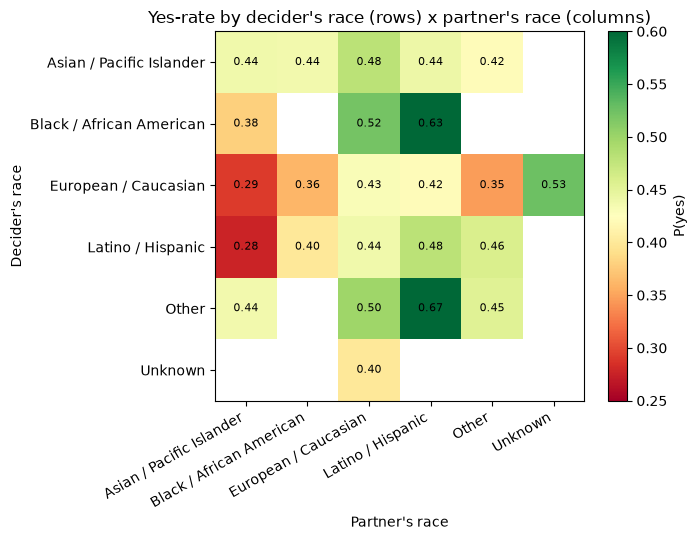

Blank cells = fewer than 30 dates, too thin to interpret.


In [17]:
# Homophily check: does the yes-rate depend on the COMBINATION of the two races?
pairs = pd.DataFrame({"decider": race_lab, "partner": race_o_lab, "dec": df["dec"]})
homophily = pairs.pivot_table(index="decider", columns="partner", values="dec", aggfunc="mean")
counts    = pairs.pivot_table(index="decider", columns="partner", values="dec", aggfunc="size")

# Blank out cells backed by too few dates to read anything into.
homophily = homophily.where(counts >= 30)

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(homophily.values, cmap="RdYlGn", vmin=0.25, vmax=0.60)
ax.set_xticks(range(homophily.shape[1])); ax.set_xticklabels(homophily.columns, rotation=30, ha="right")
ax.set_yticks(range(homophily.shape[0])); ax.set_yticklabels(homophily.index)
ax.set_title("Yes-rate by decider's race (rows) x partner's race (columns)")
ax.set_xlabel("Partner's race"); ax.set_ylabel("Decider's race")
for i in range(homophily.shape[0]):
    for j in range(homophily.shape[1]):
        v = homophily.values[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="P(yes)")
plt.tight_layout(); plt.show()

print("Blank cells = fewer than 30 dates, too thin to interpret.")

**What to notice:** the sample is **heavily skewed** — European/Caucasian participants are the majority,
while some groups have only a couple of dozen people. Two consequences for the project:

1. A **race**-based fairness metric would rest on very thin cells, which is why our proposal uses
   **gender**-exposure fairness instead. We should say so explicitly rather than leave it unexplained.
2. Race is still usable as a *feature* (`samerace` is complete and cheap), but any per-race result must
   be reported with its group size attached.

This skew also belongs in the "ecological validity" limitation of the proposal: the population is
2002–2004 US graduate students, not a modern dating platform.

### 8.1 Stated importance of same race — reading the gender gap

`imprace` is a **signup** question, answered once per person before any date happened:
*"How important is it to you (1–10) that a person you date be of the same racial/ethnic
background?"* It is therefore a `people` statistic — averaging it over date rows would silently
weight each person by how many dates they had. Section 8 printed the two means; this section asks
whether the gap is real, what shape hides behind it, and whether the stated answer shows up in
anyone's decisions.

,participants,mean,median,share_1_to_2,share_7_to_10
gender_label,,,,,
female,269,4.115,3.000,0.416,0.259
male,275,3.360,3.000,0.491,0.173


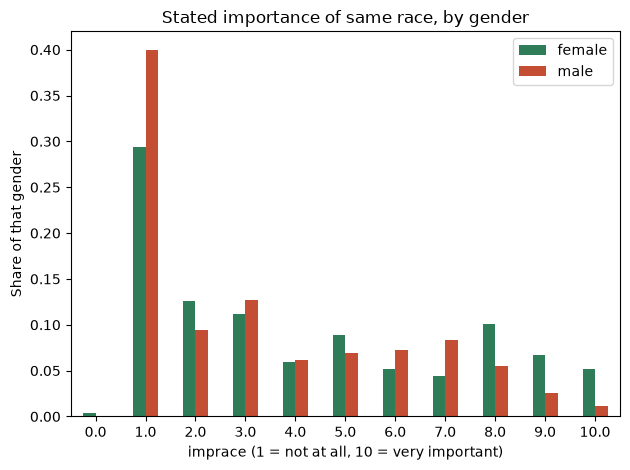

Welch t = 3.12, p = 0.0019, Cohen's d = 0.27 (269 women vs 275 men).


In [18]:
# Is the female/male gap in stated importance real, and how is the answer distributed?
from scipy import stats

imprace_by_gender = pd.DataFrame({
    "participants":  people.groupby("gender_label")["imprace"].count(),
    "mean":          people.groupby("gender_label")["imprace"].mean(),
    "median":        people.groupby("gender_label")["imprace"].median(),
    "share_1_to_2":  people.groupby("gender_label")["imprace"].apply(lambda s: (s <= 2).mean()),
    "share_7_to_10": people.groupby("gender_label")["imprace"].apply(lambda s: (s >= 7).mean()),
})
display(imprace_by_gender)

# The mean hides the shape: this is a spike at 1 with a long tail, not a bell curve.
imprace_dist = pd.crosstab(people["gender_label"], people["imprace"], normalize="index")
ax = imprace_dist.T.plot(kind="bar", color=["#2f7d58", "#c44e34"])
ax.set_title("Stated importance of same race, by gender")
ax.set_xlabel("imprace (1 = not at all, 10 = very important)")
ax.set_ylabel("Share of that gender")
plt.xticks(rotation=0); plt.legend(title="")
plt.tight_layout(); plt.show()

# Welch t-test (unequal variances, unequal group sizes) + Cohen's d for the effect size.
f = people.loc[people["gender_label"] == "female", "imprace"].dropna()
m = people.loc[people["gender_label"] == "male",   "imprace"].dropna()
t_stat, p_val = stats.ttest_ind(f, m, equal_var=False)
cohens_d = (f.mean() - m.mean()) / np.sqrt((f.var() + m.var()) / 2)
print(f"Welch t = {t_stat:.2f}, p = {p_val:.4f}, Cohen's d = {cohens_d:.2f} "
      f"({len(f)} women vs {len(m)} men).")

In [19]:
# Stated vs revealed: does the signup answer show up in the actual yes/no decisions?
# For each (gender, stated-importance) group, compare the yes-rate on same-race dates
# against different-race dates. `dec` is the decider's own choice, so this is one-sided.
dates = df.dropna(subset=["imprace", "samerace", "dec"]).copy()
dates["gender_label"] = dates["gender"].map(GENDER_LABELS)
dates["stated"] = pd.cut(dates["imprace"], [0, 3, 6, 10],
                         labels=["says 1-3", "says 4-6", "says 7-10"])

revealed = dates.pivot_table(index=["gender_label", "stated"], columns="samerace",
                             values="dec", aggfunc="mean", observed=True)
sizes    = dates.pivot_table(index=["gender_label", "stated"], columns="samerace",
                             values="dec", aggfunc="size", observed=True)
revealed.columns = ["yes_diff_race", "yes_same_race"]
revealed["gap_pp"]  = (revealed["yes_same_race"] - revealed["yes_diff_race"]) * 100
revealed["n_dates"] = sizes.sum(axis=1)
display(revealed)

yes_diff_race  yes_same_race  gap_pp  n_dates
gender_label stated                                                  
female       says 1-3           0.377          0.381   0.431     2202
             says 4-6           0.395          0.401   0.512      835
             says 7-10          0.240          0.407  16.797     1080
male         says 1-3           0.531          0.483  -4.808     2533
             says 4-6           0.446          0.510   6.339      856
             says 7-10          0.295          0.419  12.394      785

**What to notice.** Three readings, in order of how much weight they can carry.

1. **The gender gap is real but small.** Women average **4.12**, men **3.36** (Welch t = 3.12,
   p = 0.002, Cohen's d = 0.27). Statistically clear at n ≈ 545, substantively a *small* effect
   — it should not carry a large claim in the report.
2. **The mean hides the shape.** The **median is 3 for both genders**; the distribution is a spike
   at 1 with a long tail, not a bell. The gap comes almost entirely from the top of the scale:
   **25.9%** of women answer ≥ 7 versus **17.3%** of men. So the honest reading is not "women care
   more about race" — it is "the same large majority of both genders does not care, but the
   minority who does is bigger and more extreme among women."
3. **The stated answer predicts behaviour, but only at the top of the scale.** People who answer
   1–3 behave as though race is irrelevant (women flat at ~38%; men actually say yes *slightly
   more* across race lines, 53.1% vs 48.3%). People who answer 7–10 drop **12–17 points** in
   yes-rate when the partner is a different race.

Point 3 is the justification for the `race_importance = imprace * samerace` feature built in
Section 13.1: the signal lives in the **interaction**, so neither `imprace` nor `samerace` on its
own would expose it — a model given only the main effects would miss the group where race actually
drives the decision.

Two caveats that belong in the write-up. `imprace` is **self-reported on a socially sensitive
question**, so it is plausibly understated, and possibly understated *differently* by gender —
which would make the observed gap a lower bound rather than a clean measurement. And the *level*
of these numbers belongs with the ecological-validity limitation above: 2002–2004 Columbia
graduate students, not a modern dating platform. The *structure* (a small, decisive minority) is
the part more likely to travel.

## 9. Popularity (desirability) — our baseline, examined

This section deserves more attention than any other distribution in the notebook, because
**popularity *is* our baseline recommender**. The proposal defines it as: score each person by how
often they receive a "yes" from the partners they met, then rank candidates by that score, ignoring
who is doing the choosing.

A convenient property of this file: on a person's own rows, `dec_o` **is** each partner's decision
*about them*. So desirability needs no join at all — just a group-by on `iid`.

$$\text{desirability}(u) = \frac{\#\{\text{partners who said yes to } u\}}{\#\{\text{partners } u \text{ met}\}}$$

In [20]:

# Desirability = fraction of a person's partners who said yes to them.
pop = df.groupby("iid").agg(
    n_dates=("dec_o", "size"),
    n_yes=("dec_o", "sum"),
)
pop["desirability"] = pop["n_yes"] / pop["n_dates"]
pop = pop.join(people[["gender_label", "race_label", "age", "wave"]])

# VALIDATION: compute the same quantity the other way round -- from the MIRROR rows, where the
# partner records their own `dec` and we look the person up via `pid`. The two should agree.
from_mirror = df.groupby("pid")["dec"].mean()
gap = (pop["desirability"] - from_mirror.reindex(pop.index)).abs()
n_off = int((gap > 1e-9).sum())

print(f"People whose two computations disagree: {n_off} of {len(pop)} (largest gap {gap.max():.3f})")
print(f"Cause: {df['pid'].isna().sum()} date rows have a missing `pid`, so those dates never appear "
      "on the mirror side.")
print("`dec_o` on a person's own rows has NO missing values, so it is the reliable source -- "
      "that is the definition we use above.")

display(pop.head())

People whose two computations disagree: 9 of 551 (largest gap 0.089)
Cause: 10 date rows have a missing `pid`, so those dates never appear on the mirror side.
`dec_o` on a person's own rows has NO missing values, so it is the reliable source -- that is the definition we use above.


,n_dates,n_yes,desirability,gender_label,race_label,age,wave
iid,,,,,,,
1,10,5,0.500,female,Asian / Pacific Islander,21.000,1
2,10,6,0.600,female,European / Caucasian,24.000,1
3,10,5,0.500,female,European / Caucasian,25.000,1
4,10,6,0.600,female,European / Caucasian,23.000,1
5,10,3,0.300,female,European / Caucasian,21.000,1


,count,mean,std,min,25%,50%,75%,max
gender_label,,,,,,,,
female,274.000,0.479,0.239,0.000,0.280,0.500,0.667,1.000
male,277.000,0.372,0.228,0.000,0.200,0.333,0.500,0.944


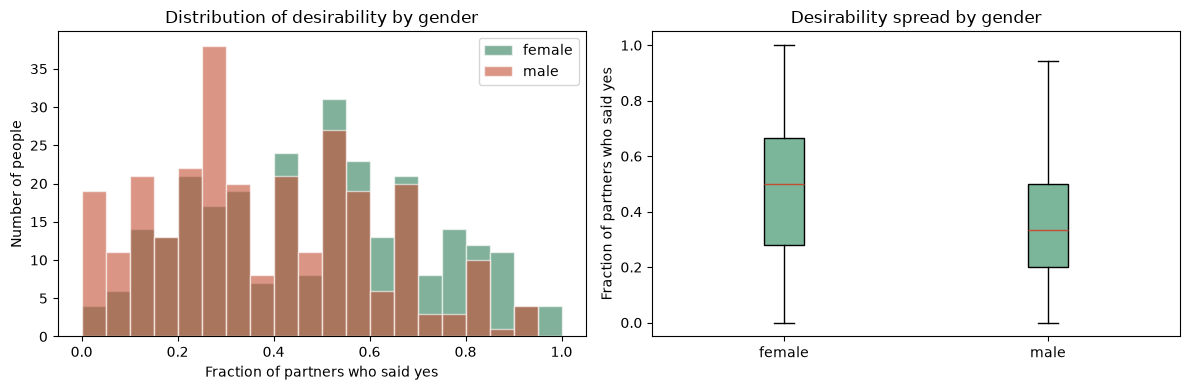

Mean desirability — female 47.9%, male 37.2% (gap 10.8 percentage points).


In [21]:
# Distribution of desirability, split by gender.
desc = pop.groupby("gender_label")["desirability"].describe()
display(desc)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

bins = np.linspace(0, 1, 21)
for g, colour in [("female", "#2f7d58"), ("male", "#c44e34")]:
    ax[0].hist(pop.loc[pop["gender_label"] == g, "desirability"],
               bins=bins, alpha=0.6, label=g, color=colour, edgecolor="white")
ax[0].set_title("Distribution of desirability by gender")
ax[0].set_xlabel("Fraction of partners who said yes"); ax[0].set_ylabel("Number of people")
ax[0].legend()

ax[1].boxplot([pop.loc[pop["gender_label"] == g, "desirability"].dropna() for g in ["female", "male"]],
              tick_labels=["female", "male"], patch_artist=True,
              boxprops=dict(facecolor="#7bb59a"), medianprops=dict(color="#c44e34"))
ax[1].set_title("Desirability spread by gender")
ax[1].set_ylabel("Fraction of partners who said yes")

plt.tight_layout(); plt.show()

means = pop.groupby("gender_label")["desirability"].mean()
gap_pp = abs(means["female"] - means["male"]) * 100
print(f"Mean desirability — female {means['female']:.1%}, male {means['male']:.1%} "
      f"(gap {gap_pp:.1f} percentage points).")

In [22]:
# Top 10 most popular people in each gender.
# Ranked by RATE, with the raw count shown too: ranking by raw `n_yes` alone would simply
# favour whoever happened to attend a large wave.
cols = ["wave", "age", "race_label", "n_dates", "n_yes", "desirability"]

for g in ["female", "male"]:
    top10 = (pop[pop["gender_label"] == g]
             .sort_values(["desirability", "n_yes"], ascending=False)
             .head(10)[cols])
    print(f"Top 10 most popular — {g}")
    display(top10)

Top 10 most popular — female


,wave,age,race_label,n_dates,n_yes,desirability
iid,,,,,,
208,9,25.000,Black / African American,20,20,1.000
456,18,29.000,Asian / Pacific Islander,6,6,1.000
132,6,27.000,European / Caucasian,5,5,1.000
268,11,24.000,Latino / Hispanic,21,20,0.952
207,9,23.000,European / Caucasian,20,19,0.950
26,2,23.000,European / Caucasian,16,15,0.938
27,2,22.000,Latino / Hispanic,16,15,0.938
180,8,24.000,Asian / Pacific Islander,10,9,0.900
389,15,21.000,European / Caucasian,19,17,0.895


Top 10 most popular — male


,wave,age,race_label,n_dates,n_yes,desirability
iid,,,,,,
99,4,28.000,European / Caucasian,18,17,0.944
366,14,27.000,European / Caucasian,20,18,0.900
19,1,28.000,European / Caucasian,10,9,0.900
20,1,24.000,European / Caucasian,10,9,0.900
250,10,25.000,Other,9,8,0.889
422,16,26.000,European / Caucasian,6,5,0.833
460,18,33.000,European / Caucasian,6,5,0.833
169,7,28.000,European / Caucasian,16,13,0.812
491,19,29.000,Latino / Hispanic,15,12,0.800


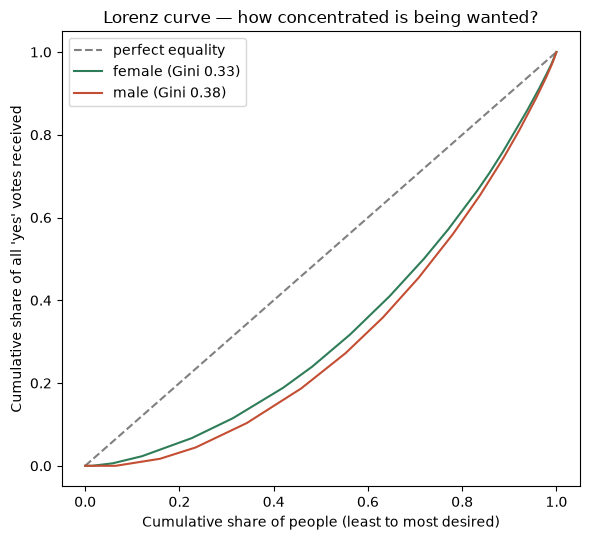

Gini over all participants: 0.363
The most desirable 10% of people absorb 22.8% of all 'yes' votes.
4.0% of participants never received a single 'yes'.

Calibration -- if every person had the SAME yes-rate and only n_dates varied:
  Gini would already be 0.186, and the top 10% would already absorb 14.3%.
  Gini of the desirability RATE itself (candidate-set size removed): 0.323


In [23]:
# How CONCENTRATED is desirability? This is the popularity-bias risk, measured.
def gini(x):
    """Gini coefficient: 0 = everyone equally desired, 1 = one person takes every yes."""
    x = np.sort(np.asarray(x, dtype=float))
    n = x.size
    if n == 0 or x.sum() == 0:
        return np.nan
    idx = np.arange(1, n + 1)
    return (2 * (idx * x).sum()) / (n * x.sum()) - (n + 1) / n


def lorenz(x):
    """Cumulative share of people (x) vs cumulative share of 'yes' votes they receive (y)."""
    x = np.sort(np.asarray(x, dtype=float))
    cum = np.cumsum(x)
    return (np.insert(np.arange(1, x.size + 1) / x.size, 0, 0),
            np.insert(cum / cum[-1], 0, 0))


fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect equality")
for g, colour in [("female", "#2f7d58"), ("male", "#c44e34")]:
    yes = pop.loc[pop["gender_label"] == g, "n_yes"]
    xs, ys = lorenz(yes)
    ax.plot(xs, ys, color=colour, label=f"{g} (Gini {gini(yes):.2f})")
ax.set_title("Lorenz curve — how concentrated is being wanted?")
ax.set_xlabel("Cumulative share of people (least to most desired)")
ax.set_ylabel("Cumulative share of all 'yes' votes received")
ax.legend()
plt.tight_layout(); plt.show()

top_n = int(round(0.10 * len(pop)))
print(f"Gini over all participants: {gini(pop['n_yes']):.3f}")
top_decile = pop["n_yes"].nlargest(top_n).sum() / pop["n_yes"].sum()
print(f"The most desirable 10% of people absorb {top_decile:.1%} of all 'yes' votes.")
print(f"{(pop['n_yes'] == 0).mean():.1%} of participants never received a single 'yes'.")

# CAUTION: the two numbers above are computed on the RAW COUNT of yes votes, which rewards
# whoever simply met more partners. Calibrate them against a world where everyone is equally
# desirable and ONLY the candidate-set size varies -- that is the share of the inequality that
# is a wave-size artefact rather than desirability.
equal_rate = pop["n_dates"] * (pop["n_yes"].sum() / pop["n_dates"].sum())
print(f"\nCalibration -- if every person had the SAME yes-rate and only n_dates varied:")
print(f"  Gini would already be {gini(equal_rate):.3f}, "
      f"and the top 10% would already absorb {equal_rate.nlargest(top_n).sum() / equal_rate.sum():.1%}.")
print(f"  Gini of the desirability RATE itself (candidate-set size removed): "
      f"{gini(pop['desirability']):.3f}")


**What to notice:** desirability really is **concentrated at the top** — a minority of people absorb
a disproportionate share of all "yes" votes, and about 4% receive none at all.

Read the headline Gini (0.363 on raw vote counts) with the calibration line above, though. Because
candidate-set sizes are unequal, a world in which **everyone is equally desirable** and only
`n_dates` varies would already produce a Gini of 0.186 and a top-10% share of 14.3%. Removing that
artefact, the Gini of the desirability *rate* is **0.323** — still substantial, just smaller than
the raw 0.363 implies.

That residual inequality is exactly the failure mode our proposal names in Section 7. A popularity
ranker recommends the same small set of highly-desired people to *everybody*, so:

- it can score respectably on **accuracy** metrics while being useless as a product;
- it will have **poor catalogue coverage** — which is precisely why **Coverage@3** is the
  beyond-accuracy metric on slide 5, and the trade-off the research question explicitly asks about.

The spread also tells us the baseline is not trivial: there really is a global desirability signal to beat.


## 10. Can we actually evaluate this? — positives per user and fold health

Our proposal commits to two things that have never been checked in code:

1. **Ranking metrics per user.** NDCG@3, Precision@3 and MRR are only defined for a user who has
   *at least one relevant item* in their candidate list. Slide 5 fixes the relevance label as the
   **mutual match**. How many participants have none?
2. **Leave-one-wave-out cross-validation.** 21 folds, each a whole event. Are the folds comparable
   enough for a mean across them to mean anything?

If either assumption fails we need to know *now*, not after the first results table.

In [24]:
# Relevant items per user, under both label definitions used in the proposal.
per_user = df.groupby("iid").agg(
    n_candidates=("dec", "size"),   # the partners we would rank for this person
    n_dec_yes=("dec", "sum"),       # directional training target: this person's one-sided 'yes'
    n_match=("match", "sum"),       # RELEVANCE LABEL (slide 5): mutual matches
)
display(per_user.describe())

no_dec   = (per_user["n_dec_yes"] == 0).mean()
no_match = (per_user["n_match"] == 0).mean()
print(f"Users with NO one-sided 'yes' given (no directional positives): {no_dec:.1%}")
print(f"Users with NO mutual match          (undefined MRR/NDCG@3):  {no_match:.1%}")
print(f"Users who never RECEIVED a 'yes':                             {(pop['n_yes'] == 0).mean():.1%}")

,n_candidates,n_dec_yes,n_match
count,551.000,551.000,551.000
mean,15.205,6.385,2.505
std,5.014,4.389,2.287
min,5.000,0.000,0.000
25%,10.000,3.000,1.000
50%,16.000,6.000,2.000
75%,20.000,9.000,4.000
max,22.000,21.000,14.000


Users with NO one-sided 'yes' given (no directional positives): 5.6%
Users with NO mutual match          (undefined MRR/NDCG@3):  18.0%
Users who never RECEIVED a 'yes':                             4.0%


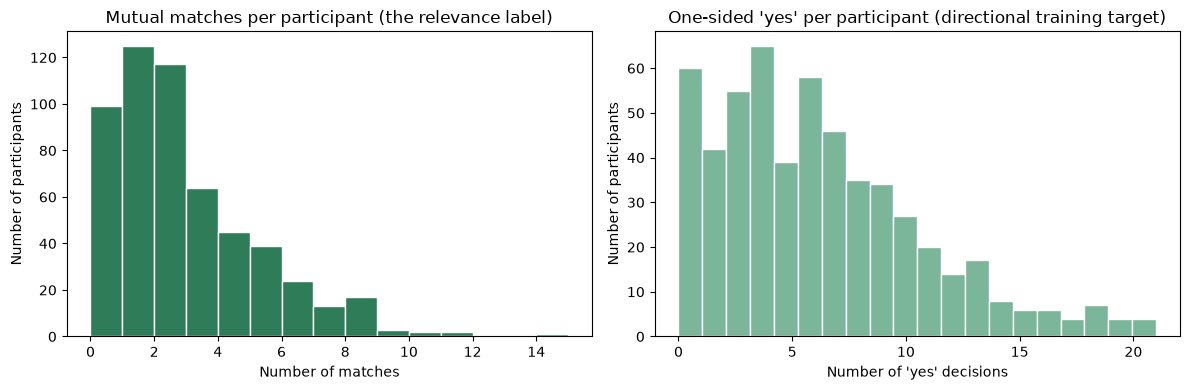

Median matches per user: 2 out of a median 16 candidates.
With a median of 2 matches, Precision@3 is capped at 2/3 for half the users and lower still
for the rest -- compare methods to each other, never against a theoretical 1.0.


In [25]:
# How many relevant items does a typical user have to find?
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

per_user["n_match"].plot(kind="hist", bins=range(0, int(per_user["n_match"].max()) + 2),
                         ax=ax[0], color="#2f7d58", edgecolor="white")
ax[0].set_title("Mutual matches per participant (the relevance label)")
ax[0].set_xlabel("Number of matches"); ax[0].set_ylabel("Number of participants")

per_user["n_dec_yes"].plot(kind="hist", bins=20, ax=ax[1], color="#7bb59a", edgecolor="white")
ax[1].set_title("One-sided 'yes' per participant (directional training target)")
ax[1].set_xlabel("Number of 'yes' decisions"); ax[1].set_ylabel("Number of participants")

plt.tight_layout(); plt.show()

print(f"Median matches per user: {per_user['n_match'].median():.0f} "
      f"out of a median {per_user['n_candidates'].median():.0f} candidates.")
print("With a median of 2 matches, Precision@3 is capped at 2/3 for half the users and lower "
      "still\nfor the rest -- compare methods to each other, never against a theoretical 1.0.")

,participants,dates,mean_cand_set,yes_rate,match_rate,pct_users_no_match
wave,,,,,,
1,20,200,10.000,0.555,0.310,0.100
2,35,608,17.371,0.373,0.102,0.286
3,20,200,10.000,0.335,0.130,0.250
4,36,648,18.000,0.429,0.201,0.111
5,19,190,10.000,0.500,0.284,0.211
6,10,50,5.000,0.500,0.200,0.200
7,32,512,16.000,0.430,0.168,0.125
8,20,200,10.000,0.430,0.180,0.150
9,40,800,20.000,0.430,0.155,0.150


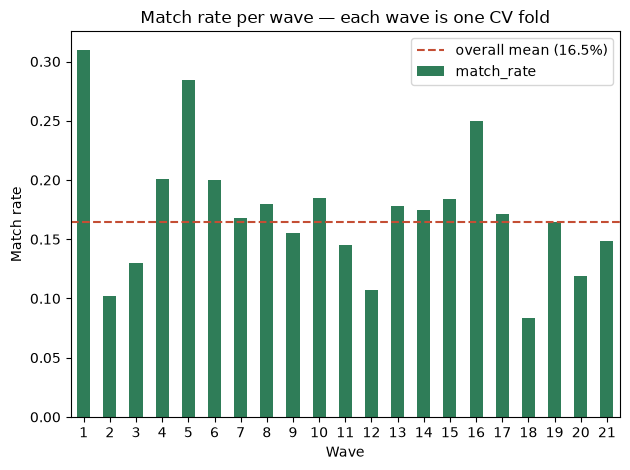

Match rate ranges from 8.3% (wave 18) to 31.0% (wave 1) — a 3.7x difference.


In [26]:
# Fold health: is every wave a usable test fold?
fold_health = pd.DataFrame({
    "participants":   df.groupby("wave")["iid"].nunique(),
    "dates":          df.groupby("wave").size(),
    "mean_cand_set":  df.groupby("wave").size() / df.groupby("wave")["iid"].nunique(),
    "yes_rate":       df.groupby("wave")["dec"].mean(),
    "match_rate":     df.groupby("wave")["match"].mean(),
})
fold_health["pct_users_no_match"] = (
    df.groupby(["wave", "iid"])["match"].sum().groupby("wave").apply(lambda s: (s == 0).mean())
)
display(fold_health)

ax = fold_health["match_rate"].plot(kind="bar", color="#2f7d58")
ax.axhline(df["match"].mean(), color="#c44e34", linestyle="--",
           label=f"overall mean ({df['match'].mean():.1%})")
ax.set_title("Match rate per wave — each wave is one CV fold")
ax.set_xlabel("Wave"); ax.set_ylabel("Match rate")
ax.legend(); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

lo, hi = fold_health["match_rate"].min(), fold_health["match_rate"].max()
print(f"Match rate ranges from {lo:.1%} (wave {fold_health['match_rate'].idxmin()}) "
      f"to {hi:.1%} (wave {fold_health['match_rate'].idxmax()}) — a {hi / lo:.1f}x difference.")

**What to notice:** two concrete consequences for the evaluation code we are about to write.

1. **A sizeable minority of users have no relevant item at all** — 18.0% have no mutual match, and
   5.6% never said yes to anyone. Their MRR is undefined and their NDCG is either 0 or undefined
   depending on convention. The evaluator must make an explicit choice — *skip these users* or
   *score them 0* — and the write-up must state which, because the two conventions can differ by
   several points and are not comparable.
2. **The folds are not equivalent.** The per-wave match rate runs from **8.3% (wave 18) to 31.0%
   (wave 1) — a 3.7× spread** — so an absolute score from one held-out wave is not meaningful on
   its own. Reporting the **mean and standard deviation across the 21 folds**, as the proposal
   already promises, is not a formality here; a single unusual wave can visibly move the average.

No wave has to be dropped — every one has a non-zero match rate — but two will be noisy and should
be read with their size attached: **wave 18** (12 participants, 6 candidates each, and 58% of its
users with no match at all) and **wave 6** (10 participants, 5 candidates each). At those sizes a
top-3 cut-off is half the candidate list, so Coverage@3 will look artificially healthy there.


### 10.1 A confound the data key reveals: `condtn`

The key documents a column the rest of this notebook has ignored: **`condtn` — "experimental
condition: 1 = limited choice, 2 = extensive choice"**. This is not an observation, it is a
**designed manipulation**, and it is constant within each wave — which means it is perfectly
confounded with the unit we split on. Before we read the fold-to-fold spread above as noise, we
should check how much of it is the experiment doing what it was designed to do.

In [27]:
# `condtn` is a wave-level treatment: check it is constant within each wave, then measure it.
cond_by_wave = df.drop_duplicates("iid").groupby("wave")["condtn"].agg(["nunique", "first"])
print(f"Waves where `condtn` varies within the wave: {int((cond_by_wave['nunique'] > 1).sum())}")
print(f"Condition 1 (limited choice) waves:   {sorted(cond_by_wave.index[cond_by_wave['first'] == 1])}")
print(f"Condition 2 (extensive choice) waves: {sorted(cond_by_wave.index[cond_by_wave['first'] == 2])}")

by_cond = df.groupby("condtn").agg(
    dates=("dec", "size"), yes_rate=("dec", "mean"), match_rate=("match", "mean"),
)
by_cond["mean_candidate_set"] = (df.groupby("condtn").size()
                                 / df.groupby("condtn")["iid"].nunique())
display(by_cond)

# How much of the per-wave match-rate spread is the manipulation rather than noise?
fold = fold_health[["match_rate"]].join(cond_by_wave["first"].rename("condtn"))
fold["cand_set"] = fold_health["mean_cand_set"]
resid = fold.groupby("condtn")["match_rate"].transform(lambda s: s - s.mean())
r2_cond = 1 - resid.var() / fold["match_rate"].var()
r_cond_size = fold["condtn"].corr(fold["cand_set"])

yes_gap   = (by_cond.loc[1, "yes_rate"]   - by_cond.loc[2, "yes_rate"])   * 100
match_gap = (by_cond.loc[1, "match_rate"] - by_cond.loc[2, "match_rate"]) * 100
print(f"Limited choice minus extensive choice: yes-rate {yes_gap:+.1f}pp, "
      f"match rate {match_gap:+.1f}pp")
print(f"Per-wave match-rate variance explained by `condtn`: R2 = {r2_cond:.3f}")
print(f"Correlation between `condtn` and candidate-set size: {r_cond_size:+.3f}")
print()
print("That last number is the important one: 'limited vs extensive choice' WAS operationalised")
print("as candidate-set size. The two are the same manipulation, not two separate variables.")

Waves where `condtn` varies within the wave: 0
Condition 1 (limited choice) waves:   [1, 3, 5, 6, 8, 10, 13, 16, 18, 20]
Condition 2 (extensive choice) waves: [2, 4, 7, 9, 11, 12, 14, 15, 17, 19, 21]


,dates,yes_rate,match_rate,mean_candidate_set
condtn,,,,
1,1434,0.460,0.202,8.691
2,6944,0.412,0.157,17.990


Limited choice minus extensive choice: yes-rate +4.9pp, match rate +4.5pp
Per-wave match-rate variance explained by `condtn`: R2 = 0.105
Correlation between `condtn` and candidate-set size: +0.878

That last number is the important one: 'limited vs extensive choice' WAS operationalised
as candidate-set size. The two are the same manipulation, not two separate variables.


**What to notice:** three things follow, and none of them were visible before reading the key.

**Part of the fold spread is by design.** People in the limited-choice condition say yes to
**46.0%** of partners against **41.2%** in the extensive condition, and match at **20.2%** against
**15.7%**. The manipulation explains about a tenth of the per-wave match-rate variance. The
8.3%–31.0% spread in Section 10 is therefore *partly structural* — not purely the small-sample
noise the Section 10 reading implied. The recommendation is unchanged (report mean and standard
deviation across folds) but the reason is stronger: some folds are systematically harder.

**Candidate-set size is a treatment, not an accident.** `condtn` correlates **+0.88** with mean
candidate-set size — limited-choice waves are the small waves. This matters directly for the
metrics on slide 5: Precision@3 and Coverage@3 both depend on how many candidates there are, so a
fold's score is partly determined by which arm of the experiment it belongs to. Comparing raw
per-fold numbers across conditions is comparing two different experiments.

**But `condtn` cannot be used as a ranking feature.** It is constant within a wave, and ranking
happens *within* a person's wave — a constant cannot reorder anything. It belongs in the analysis
and the limitations, not in the feature matrix.


## 11. What actually drives a decision — feature signal checks

Our improved method predicts $P(A \text{ says yes to } B)$ from the pair's features. Before fitting
anything, we check that the intended features separate a "yes" from a "no" at all. Three checks:

- the six attribute ratings (plus overall `like`) against the yes-rate;
- `int_corr`, the pre-computed interest-similarity feature — is it actually informative?
- `order`, the position of the date in the night — a **confound** we must not ignore.

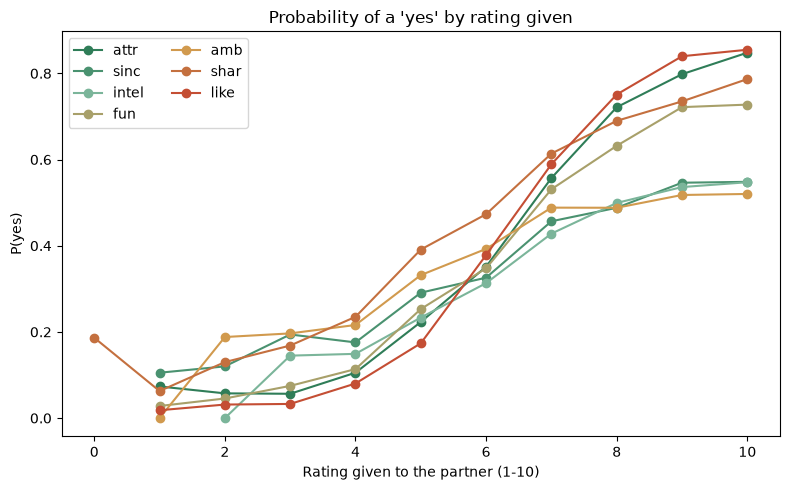

In [28]:
# Yes-rate as a function of each attribute rating.
ATTRS = ["attr", "sinc", "intel", "fun", "amb", "shar", "like"]
palette = ["#2f7d58", "#4a9270", "#7bb59a", "#a8a06a", "#d19a4e", "#c4703f", "#c44e34"]

fig, ax = plt.subplots(figsize=(8, 5))
for a, colour in zip(ATTRS, palette):
    sub = df[[a, "dec"]].dropna()
    # DELIBERATE GUARD, not a silent filter: these ratings are documented as 1-10 but the file
    # contains a few values outside that range. Section 14 audits exactly what this drops.
    sub = sub[sub[a].between(0, 10)]
    curve = sub.groupby(sub[a].round())["dec"].agg(["mean", "size"])
    curve = curve[curve["size"] >= 30]        # ignore rating values with too little data
    ax.plot(curve.index, curve["mean"], marker="o", color=colour, label=a)

ax.set_title("Probability of a 'yes' by rating given")
ax.set_xlabel("Rating given to the partner (1-10)"); ax.set_ylabel("P(yes)")
ax.legend(ncol=2)
plt.tight_layout(); plt.show()

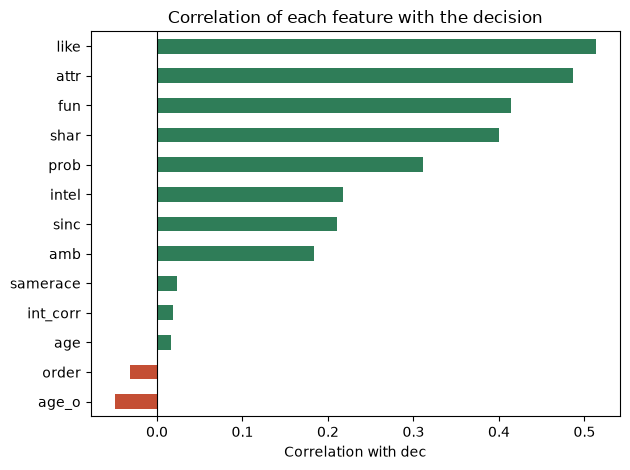

,corr_with_dec
age_o,-0.049
order,-0.032
age,0.016
int_corr,0.019
samerace,0.023
amb,0.184
sinc,0.210
intel,0.217
prob,0.311
shar,0.401


In [29]:
# Correlation of each candidate feature with the decision (point-biserial: `dec` is binary).
feature_cols = ATTRS + ["int_corr", "prob", "age", "age_o", "samerace", "order"]
corr_with_dec = (df[feature_cols]
                 .apply(lambda s: s.corr(df["dec"]))
                 .sort_values())

ax = corr_with_dec.plot(kind="barh",
                        color=["#c44e34" if v < 0 else "#2f7d58" for v in corr_with_dec])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Correlation of each feature with the decision")
ax.set_xlabel("Correlation with dec"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

display(corr_with_dec.to_frame("corr_with_dec"))

,dates,yes_rate,match_rate
int_corr,,,
"(-0.831, -0.07]",1690,0.401,0.150
"(-0.07, 0.13]",1718,0.421,0.156
"(0.13, 0.3]",1541,0.426,0.157
"(0.3, 0.48]",1715,0.419,0.167
"(0.48, 0.91]",1556,0.435,0.193


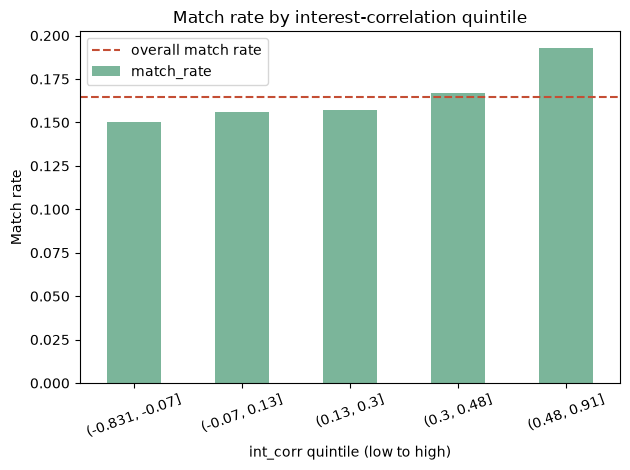

int_corr vs dec correlation: +0.019
Match-rate spread across quintiles: 4.3% (overall rate 16.5%)
For comparison, `attr` correlates with `dec` at +0.487 -- more than 20x stronger.
Verdict: int_corr is a very weak signal on its own. Keep it as a cheap extra feature, but it will not carry the model.


In [30]:

# Is `int_corr` -- the ready-made compatibility feature -- worth including?
int_bins = pd.qcut(df["int_corr"], 5, duplicates="drop")
int_signal = df.groupby(int_bins, observed=True).agg(
    dates=("match", "size"),
    yes_rate=("dec", "mean"),
    match_rate=("match", "mean"),
)
display(int_signal)

ax = int_signal["match_rate"].plot(kind="bar", color="#7bb59a")
ax.axhline(df["match"].mean(), color="#c44e34", linestyle="--", label="overall match rate")
ax.set_title("Match rate by interest-correlation quintile")
ax.set_xlabel("int_corr quintile (low to high)"); ax.set_ylabel("Match rate")
ax.legend(); plt.xticks(rotation=20)
plt.tight_layout(); plt.show()

spread = int_signal["match_rate"].max() - int_signal["match_rate"].min()
r_int = df["int_corr"].corr(df["dec"])
print(f"int_corr vs dec correlation: {r_int:+.3f}")
print(f"Match-rate spread across quintiles: {spread:.1%} (overall rate {df['match'].mean():.1%})")
print("For comparison, `attr` correlates with `dec` at "
      f"{df['attr'].corr(df['dec']):+.3f} -- more than 20x stronger.")
print("Verdict: int_corr is a very weak signal on its own. Keep it as a cheap extra feature, "
      "but it will not carry the model.")

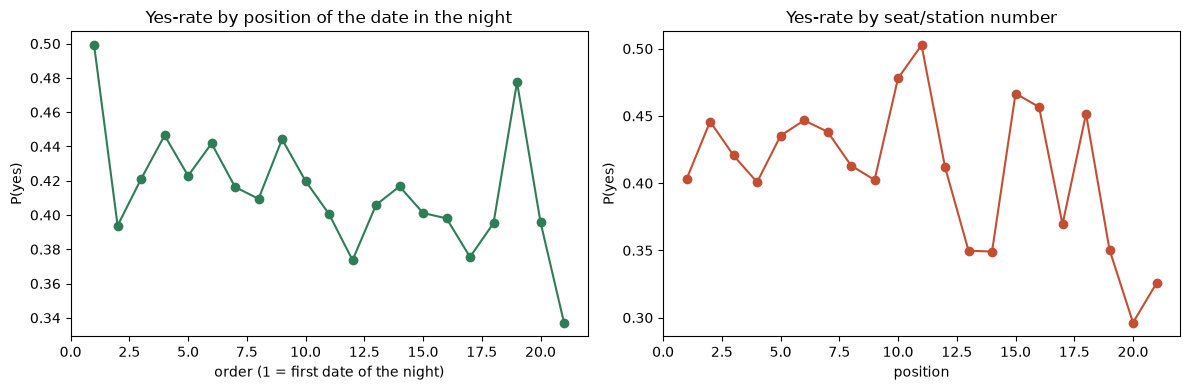

,yes_rate
order,
early,0.438
middle,0.419
late,0.399


Correlation between `order` and `dec`: -0.032
Yes-rate drifts from 43.8% early in the night to 39.9% late (3.8 percentage points).
Verdict: a mild downward drift -- people get slightly stingier as the night goes on, but this is not a serious confound. Worth re-checking if we ever model a subset of waves.


In [31]:
# Confound check: does WHEN in the night a date happened change the decision?
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

order_effect = df.groupby("order")["dec"].agg(["mean", "size"])
order_effect = order_effect[order_effect["size"] >= 50]
ax[0].plot(order_effect.index, order_effect["mean"], marker="o", color="#2f7d58")
ax[0].set_title("Yes-rate by position of the date in the night")
ax[0].set_xlabel("order (1 = first date of the night)"); ax[0].set_ylabel("P(yes)")

pos_effect = df.groupby("position")["dec"].agg(["mean", "size"])
pos_effect = pos_effect[pos_effect["size"] >= 50]
ax[1].plot(pos_effect.index, pos_effect["mean"], marker="o", color="#c44e34")
ax[1].set_title("Yes-rate by seat/station number")
ax[1].set_xlabel("position"); ax[1].set_ylabel("P(yes)")

plt.tight_layout(); plt.show()

# The per-order curve is noisy at the tail (few dates run past number 20), so summarise it in
# thirds of the night instead -- that is the robust version of the same question.
thirds = pd.qcut(df["order"], 3, labels=["early", "middle", "late"])
by_third = df.groupby(thirds, observed=True)["dec"].mean()
display(by_third.to_frame("yes_rate"))

r_order = df["order"].corr(df["dec"])
drift = by_third["early"] - by_third["late"]
print(f"Correlation between `order` and `dec`: {r_order:+.3f}")
print(f"Yes-rate drifts from {by_third['early']:.1%} early in the night "
      f"to {by_third['late']:.1%} late ({drift * 100:.1f} percentage points).")
if abs(r_order) < 0.05:
    print("Verdict: a mild downward drift -- people get slightly stingier as the night goes on, "
          "but this is not a serious confound. Worth re-checking if we ever model a subset of waves.")
else:
    print("Verdict: a real order effect -- treat `order` as a feature or control for it, "
          "or the model will learn a scheduling artefact and call it preference.")


**What to notice:** the attribute ratings are clearly ordered. `attr` (r ≈ 0.49), `fun` (0.41) and
`shar` (0.40) separate a yes from a no far more sharply than `sinc` (0.21), `intel` (0.22) or
`amb` (0.18).

Two features need care rather than enthusiasm:

- **`like` (r ≈ 0.51) is close to a restatement of the decision itself** — "how much did you like them"
  and "do you want to see them again" are nearly the same question. Including it would make the model
  look excellent while teaching us nothing transferable. The same caution applies to **`prob`** (0.31),
  which is the participant's own guess about the outcome. **Keep both out of the feature set**, or
  report results with and without them.
- **`int_corr` is far weaker than its billing suggests** (r ≈ 0.02, roughly twenty times weaker than
  `attr`). It is cheap to include, but it will not carry the model — worth knowing before we attribute
  any success to "interest compatibility".

The `order` effect turns out to be **mild** (r ≈ −0.03): people are slightly stingier later in the
night, but not enough to distort the model. We checked rather than assumed — that is the point.


## 12. Stated preferences vs observed behaviour

Two features on the proposal deck depend on the stated-preference block. Slide 4 builds **X₁** on
*gender-asymmetric clustering* — "men grouped by attributes, women by stated preferences" — and
slide 1 lists *compatibility-gap features*, "the distance between each person's stated preferences
and the partner's attribute ratings". Both assume the stated weights are (a) comparable across
waves and (b) actually different from what people do. If stated and revealed preferences agreed,
the compatibility gap would be a redundant re-encoding of the ratings and clustering women by
stated preferences would buy nothing over clustering them by behaviour.

So there are two things to establish before the modelling notebook relies on them.

First, a claim inherited from the data documentation and summarised in Section 7 above: the
preference-allocation blocks are supposedly a 100-point allocation in most waves but a 1–10 scale in
waves 6–9. If that were true of the block we use, averaging across waves without rescaling would be
meaningless. Rather than trust the prose, we measure it — first for the block we actually use, then
for every other preference block in the file.


,mean,median,min,max,size
wave,,,,,
1,99.999,100.000,99.990,100.000,20
2,100.588,100.000,100.000,120.000,35
3,102.167,100.000,90.000,148.000,20
4,99.722,100.000,90.000,100.000,36
5,100.000,100.000,100.000,100.000,19
6,100.003,100.000,99.990,100.020,10
7,100.001,100.000,99.980,100.020,32
8,100.001,100.000,99.980,100.020,20
9,100.002,100.000,99.990,100.020,40


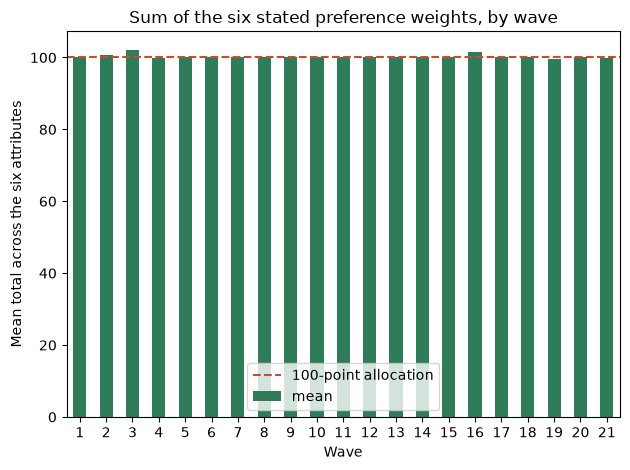

Waves whose totals look like a 1-10 scale rather than 100 points: []

FINDING (this block only): every wave of `attr1_1 ... shar1_1` already sums to ~100.
Waves 6-9 hold values like 16.67 and 12.77 -- i.e. they were collected on the 1-10
scale and have already been rescaled to a 100-point allocation for us. The next two
cells check whether that is true of the OTHER preference blocks too.

Totals are still not exactly 100 everywhere (range 90 to 148), so we normalise
each participant to shares below. That is robust either way, and costs nothing.


In [32]:

# Verify the preference-scale claim for the block we use: sum the six stated weights per
# participant, by wave.
PREF1 = ["attr1_1", "sinc1_1", "intel1_1", "fun1_1", "amb1_1", "shar1_1"]

pref = df.drop_duplicates("iid").set_index("iid")[PREF1 + ["wave", "gender"]].copy()
pref["stated_total"] = pref[PREF1].sum(axis=1, min_count=6)

scale_by_wave = pref.groupby("wave")["stated_total"].agg(["mean", "median", "min", "max", "size"])
display(scale_by_wave)

ax = scale_by_wave["mean"].plot(kind="bar", color="#2f7d58")
ax.axhline(100, color="#c44e34", linestyle="--", label="100-point allocation")
ax.set_title("Sum of the six stated preference weights, by wave")
ax.set_xlabel("Wave"); ax.set_ylabel("Mean total across the six attributes")
ax.legend(); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

ten_point_waves = scale_by_wave.index[scale_by_wave["mean"] < 50].tolist()
print(f"Waves whose totals look like a 1-10 scale rather than 100 points: {ten_point_waves}")
print()
if not ten_point_waves:
    print("FINDING (this block only): every wave of `attr1_1 ... shar1_1` already sums to ~100.")
    print("Waves 6-9 hold values like 16.67 and 12.77 -- i.e. they were collected on the 1-10")
    print("scale and have already been rescaled to a 100-point allocation for us. The next two")
    print("cells check whether that is true of the OTHER preference blocks too.")
    print()
print("Totals are still not exactly 100 everywhere "
      f"(range {scale_by_wave['min'].min():.0f} to {scale_by_wave['max'].max():.0f}), so we normalise")
print("each participant to shares below. That is robust either way, and costs nothing.")


wave,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21
participants,20.000,34.000,18.000,36.000,17.000,9.000,32.000,20.000,40.000,18.000,42.000,28.000,17.000,37.000,37.000,14.000,24.000,12.000,30.000,13.000,43.000
all_whole_numbers,18.000,34.000,18.000,36.000,17.000,0.000,7.000,0.000,5.000,18.000,41.000,27.000,17.000,35.000,37.000,14.000,24.000,12.000,30.000,13.000,43.000
pct_whole,0.900,1.000,1.000,1.000,1.000,0.000,0.219,0.000,0.125,1.000,0.976,0.964,1.000,0.946,1.000,1.000,1.000,1.000,1.000,1.000,1.000


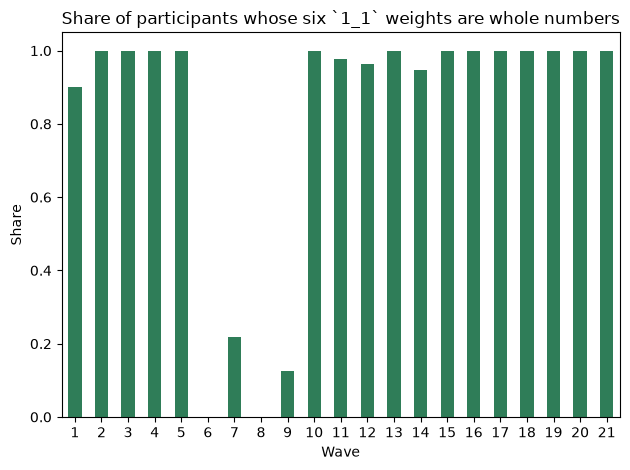

Waves where most values are NOT whole numbers (i.e. rescaled for us): [6, 7, 8, 9]
Every other wave is >90% whole numbers -- those are genuine 100-point allocations.


wave,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21
share_that_inverts_to_1-10_answers,0.600,0.588,0.389,0.556,0.765,1.000,1.000,1.000,1.000,0.722,0.524,0.714,0.647,0.649,0.568,0.571,0.458,0.500,0.700,0.538,0.581


Waves 6-9: 100% of participants invert EXACTLY to integer 1-10 answers.
All other waves: 76% at most -- the rate round-number
allocations hit by coincidence. Example, iid 133 in wave 6:
  stored: [12.77 19.15 17.02 17.02 14.89 19.15]
  -> recovered 1-10 answers: [6 9 8 8 7 9]

Conclusion: waves 6-9 of this block were collected on the 1-10 scale and converted to
100-point shares before the file was published. Nothing left for us to fix here.


In [33]:

# Summing to 100 is necessary but not sufficient: a 1-10 block could coincidentally average out.
# The decisive test is whether the values are WHOLE NUMBERS. Nobody allocating 100 points types
# "12.77" -- that shape can only come from rescaling a 1-10 answer into a share.
people_pref = df.drop_duplicates("iid").set_index("iid")
vals = people_pref[PREF1].dropna()
all_whole = vals.apply(lambda r: np.isclose(r % 1, 0).all(), axis=1)

whole_by_wave = pd.DataFrame({
    "participants": all_whole.groupby(people_pref.loc[vals.index, "wave"]).size(),
    "all_whole_numbers": all_whole.groupby(people_pref.loc[vals.index, "wave"]).sum(),
})
whole_by_wave["pct_whole"] = whole_by_wave["all_whole_numbers"] / whole_by_wave["participants"]
display(whole_by_wave.T)

ax = whole_by_wave["pct_whole"].plot(kind="bar", color="#2f7d58")
ax.set_title("Share of participants whose six `1_1` weights are whole numbers")
ax.set_xlabel("Wave"); ax.set_ylabel("Share")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

converted = whole_by_wave.index[whole_by_wave["pct_whole"] < 0.5].tolist()
print(f"Waves where most values are NOT whole numbers (i.e. rescaled for us): {converted}")
print("Every other wave is >90% whole numbers -- those are genuine 100-point allocations.")


# Final confirmation: if those decimals really are a rescaled 1-10 answer, then solving
# value_i == 100 * v_i / sum(v) must recover integers v in 1..10. Try every possible total.
def recover_1_10(values):
    """Return the integer 1-10 answers behind a set of shares, or None if there are none."""
    for total in range(6, 61):                      # six attributes, each rated 1-10
        v = np.asarray(values) * total / 100.0
        r = np.round(v)
        if np.all(np.abs(v - r) < 0.02) and r.sum() == total and r.min() >= 1 and r.max() <= 10:
            return r.astype(int)
    return None


recovered = vals.apply(lambda r: recover_1_10(r.values) is not None, axis=1)
rate = recovered.groupby(people_pref.loc[vals.index, "wave"]).mean()
display(rate.to_frame("share_that_inverts_to_1-10_answers").T)

print(f"Waves 6-9: {rate.loc[6:9].min():.0%} of participants invert EXACTLY to integer 1-10 answers.")
print(f"All other waves: {rate.drop([6, 7, 8, 9]).max():.0%} at most -- the rate round-number")
print("allocations hit by coincidence. Example, iid 133 in wave 6:")
print(f"  stored: {vals.loc[133].values}")
print(f"  -> recovered 1-10 answers: {recover_1_10(vals.loc[133].values)}")
print("\nConclusion: waves 6-9 of this block were collected on the 1-10 scale and converted to")
print("100-point shares before the file was published. Nothing left for us to fix here.")


In [34]:

# Now the same scale test across EVERY preference-allocation block in the file.
# Groups 1/2/4/7 are 100-point allocations over the six attributes; groups 3 and 5 are
# self- and perception-ratings that are 1-10 by design, so they are excluded here.
BLOCKS = ["1_1", "4_1", "2_1", "1_s",
          "1_2", "4_2", "2_2", "7_2",
          "1_3", "4_3", "2_3", "7_3"]
ATTR_STEMS = ["attr", "sinc", "intel", "fun", "amb", "shar"]

rows = []
for block in BLOCKS:
    cols = [f"{stem}{block}" for stem in ATTR_STEMS]
    if not all(c in people_pref.columns for c in cols):
        continue
    total = people_pref[cols].sum(axis=1, min_count=6)
    mean_by_wave = total.groupby(people_pref["wave"]).mean()
    present = sorted(int(w) for w in mean_by_wave.dropna().index)
    low = sorted(int(w) for w in mean_by_wave.index if pd.notna(mean_by_wave[w]) and mean_by_wave[w] < 60)
    clean = [w for w in present if w not in low]
    rows.append({
        "block": block,
        "waves_present": f"{min(present)}-{max(present)}" if present else "-",
        "mean_on_100pt_waves": round(mean_by_wave.loc[clean].mean(), 1) if clean else np.nan,
        "mean_on_1_10_waves": round(mean_by_wave.loc[low].mean(), 1) if low else np.nan,
        "waves_still_on_1_10": low or "none",
    })

block_scales = pd.DataFrame(rows).set_index("block")
display(block_scales)

broken = block_scales[block_scales["waves_still_on_1_10"] != "none"]
print("FINDING: the documented scale problem is REAL, but not in the block this project uses.")
print()
for block, row in broken.iterrows():
    print(f"  {block:<5} still on the raw 1-10 scale in waves {row['waves_still_on_1_10']}")
print()
print("`attr1_1 ... shar1_1` -- the block this project uses -- is clean in all 21 waves.")
print("Note `1_s`: the data key blames waves 6-9, but for that block waves 6-9 are fine and")
print("waves 18-20 are the ones on the 1-10 scale. Anything downstream using `4_1` (a pre-date,")
print("leakage-safe feature) or `1_s` must rescale to shares first.")


,waves_present,mean_on_100pt_waves,mean_on_1_10_waves,waves_still_on_1_10
block,,,,
1_1,1-21,100.200,NaN,none
4_1,6-21,99.900,44.000,"[6, 7, 8, 9]"
2_1,1-21,100.000,NaN,none
1_s,6-20,100.000,44.500,"[18, 19, 20]"
1_2,1-21,100.000,NaN,none
4_2,6-21,100.100,44.600,"[6, 7, 8, 9]"
2_2,6-21,99.900,NaN,none
7_2,15-21,97.900,NaN,none
1_3,1-21,100.100,NaN,none


FINDING: the documented scale problem is REAL, but not in the block this project uses.

  4_1   still on the raw 1-10 scale in waves [6, 7, 8, 9]
  1_s   still on the raw 1-10 scale in waves [18, 19, 20]
  4_2   still on the raw 1-10 scale in waves [6, 7, 8, 9]
  4_3   still on the raw 1-10 scale in waves [6, 7, 8, 9]

`attr1_1 ... shar1_1` -- the block this project uses -- is clean in all 21 waves.
Note `1_s`: the data key blames waves 6-9, but for that block waves 6-9 are fine and
waves 18-20 are the ones on the 1-10 scale. Anything downstream using `4_1` (a pre-date,
leakage-safe feature) or `1_s` must rescale to shares first.


In [35]:
# Rescale every participant's stated weights to shares that sum to 1, then average by gender.
stated_shares = pref[PREF1].div(pref["stated_total"], axis=0)
stated_shares.columns = ["attr", "sinc", "intel", "fun", "amb", "shar"]
stated = stated_shares.join(pref["gender"]).groupby("gender").mean()
stated.index = stated.index.map(GENDER_LABELS)

# 'Revealed' weights: how strongly each attribute rating actually tracks the decision, per gender,
# normalised to sum to 1 so it is on the same footing as the stated shares.
# Deliberately correlation-based (numpy/pandas only) -- descriptive, not a fitted model.
ATTR6 = ["attr", "sinc", "intel", "fun", "amb", "shar"]
revealed = {}
for code, label in GENDER_LABELS.items():
    sub = df[df["gender"] == code]
    c = sub[ATTR6].corrwith(sub["dec"]).clip(lower=0)
    revealed[label] = c / c.sum()
revealed = pd.DataFrame(revealed).T

comparison = pd.concat({"stated": stated, "revealed": revealed}, axis=0)
display(comparison)

attr  sinc  intel   fun   amb  shar
         gender                                     
stated   female 0.179 0.183  0.209 0.173 0.128 0.127
         male   0.270 0.164  0.194 0.176 0.087 0.109
revealed female 0.234 0.117  0.122 0.219 0.092 0.217
         male   0.266 0.099  0.112 0.210 0.113 0.200

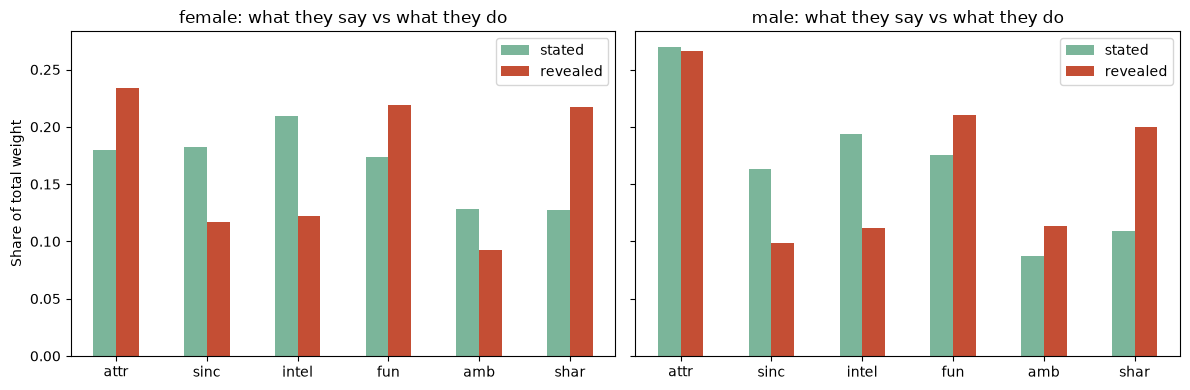

Revealed minus stated (positive = matters more in practice than people admit):


,attr,sinc,intel,fun,amb,shar
female,0.054,-0.066,-0.087,0.045,-0.036,0.090
male,-0.004,-0.065,-0.082,0.035,0.026,0.091


In [36]:
# Stated vs revealed, side by side.
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for i, g in enumerate(["female", "male"]):
    side = pd.DataFrame({"stated": stated.loc[g], "revealed": revealed.loc[g]})
    side.plot(kind="bar", ax=ax[i], color=["#7bb59a", "#c44e34"])
    ax[i].set_title(f"{g}: what they say vs what they do")
    ax[i].set_xlabel(""); ax[i].set_ylabel("Share of total weight")
    ax[i].tick_params(axis="x", rotation=0)

plt.tight_layout(); plt.show()

drift = (revealed - stated).round(3)
print("Revealed minus stated (positive = matters more in practice than people admit):")
display(drift)


**What to notice:** two results, one expected and one not.

**Expected:** stated and revealed weights **do not agree**, and the gap differs by gender. This is
what the compatibility-gap feature is made of — if the two agreed, the gap would carry no
information the ratings do not already carry. The gender difference is also the empirical
justification for slide 4's **gender-asymmetric clustering**: men and women diverge from their
stated weights in different places, so grouping them on the same axis would blur exactly the
signal X₁ is trying to use.

**Not expected:** the wave 6–9 scale warning turns out to be **half right, and misfiled**.

- For `attr1_1 … shar1_1`, the block we use, every wave already sums to ~100. Waves 6–9 *were*
  collected on the 1–10 scale, but somebody has already converted them: they are the only waves
  whose values are not whole numbers — 0% whole in waves 6 and 8, 12% and 22% in waves 9 and 7,
  against 90–100% in every other wave. And those decimals invert **exactly** back to integer 1–10
  answers (100% of participants in waves 6–9 do; at most 76% elsewhere, by coincidence). The
  conversion loses the raw magnitudes but preserves the shares, which is all we use — though it
  does **not** make the two question formats interchangeable, which Section 12.1 measures.
- The raw 1–10 scale **is still in the file**, in `*4_1`, `*4_2` and `*4_3` for waves 6–9, and in
  `*1_s` for waves **18–20** — a case the data key does not mention at all, since it attributes the
  problem to waves 6–9 for every block alike.

So the warning should be **narrowed, not dropped**: harmless for the block this project uses, still
live for any downstream step that reaches for `4_1`, `4_2`, `4_3` or `1_s`.

But rescaling is not the binding constraint on those blocks — **coverage is**, and that is the more
important finding:

| block | waves present | participants with a complete block |
|---|---|---|
| `1_1` (what *I* want) | **1–21** | **541 / 551 (98.2%)** |
| `2_1` (what I think the other sex wants) | 1–21 | 543 / 551 (98.5%) |
| `4_1` (what I think my *peers* want) | **6–21 only** | 416 / 551 (75.5%) |
| `1_s` (what I want, measured mid-event) | 6–20 only | — |
| `3_1` (how I rate *myself*, 1–10) | **1–21** | **542 / 551 (98.4%)** |
| `5_1` (how I think others perceive me, 1–10) | **10–21 only** | 314 / 551 (57.0%) |

`4_1` does not exist at all for waves 1–5, `1_s` does not exist for waves 1–5 or 21, and the
`5_1` perception block only starts at wave 10. Under leave-one-wave-out cross-validation a feature
built on any of them would be entirely absent from several folds — a far worse problem than a
scale difference, and one no rescaling fixes.

Only two blocks cover all 21 waves: **`1_1`** (stated preferences) and **`3_1`** (self-ratings).
Those are the two the project uses — `1_1` for what a person wants, `3_1` as the pre-date stand-in
for what they are like (Section 15.4). Note that the `3_1` and `5_1` blocks are 1–10 by design, per
the data key: only question groups 1, 2, 4 and 7 use the 100-point allocation, so the rescaling
question does not arise for them at all.

We still normalise each participant's `1_1` block to shares, because the totals are not *exactly*
100 everywhere: the per-wave extremes run from **90 to 148**, so a few people over- or
under-allocated. That is cheap insurance, not a fix for a problem we found.

Finally, the "revealed" weights here are a descriptive correlation, **not** a fitted model — the
real comparison happens inside X₁ and X₂.

One caveat that Section 15 makes precise: the "revealed" weights are derived from **in-date**
ratings, and slide 5 requires features to be strictly pre-date. The divergence measured here is a
sound *motivation* for the compatibility-gap feature, but the feature itself has to be built from
a pre-date stand-in for the partner's attributes — see Section 15.4.


### 12.1 Converting a 1–10 answer into shares does *not* make it a 100-point answer

The result above — waves 6–9 were converted for us — is easy to over-read as "so all 21 waves are
the same thing now". They are not, and the difference matters enough to measure.

**Two different questions were asked.**

| Waves | The question participants answered | What it forces |
|---|---|---|
| 1–5, 10–21 | "You have **100 points** — distribute them across the six attributes" | A **trade-off**. Giving attractiveness 40 means something else must drop |
| 6–9 | "Rate each attribute **1–10** on how important it is to you" | **Nothing.** You may answer 9 to all six |

No arithmetic turns one into the other, and the conversion in the file
($100 \times v_i / \sum_j v_j$) does two things worth separating.

**It discards intensity.** These two people are byte-identical after conversion:

| answered on the 1–10 form | stored in the file |
|---|---|
| 9, 9, 9, 9, 9, 9 — *cares intensely about everything* | 16.67 each |
| 2, 2, 2, 2, 2, 2 — *cares about none of it* | 16.67 each |

Only the **shape** of a preference profile survives; the level is gone. For this project that is
acceptable, because every feature we build from this block uses relative weights — but it is a real
loss, not a formality.

**And the format changes how people answer**, which normalisation cannot repair. Someone forced to
split 100 points creates spread; someone rating each attribute 1–10 tends to mark several of them
high, and after normalisation that profile is *flatter*. The cell below measures whether that
happened here, comparing the two groups on the same normalised scale.

,other waves (100 points),waves 6-9 (rated 1-10)
participants,440.000,101.000
mean weight on attr,0.240,0.162
mean spread (std of 6),0.091,0.034
mean largest weight,0.295,0.200
mean smallest weight,0.068,0.116
gave some attribute 0,0.202,0.000


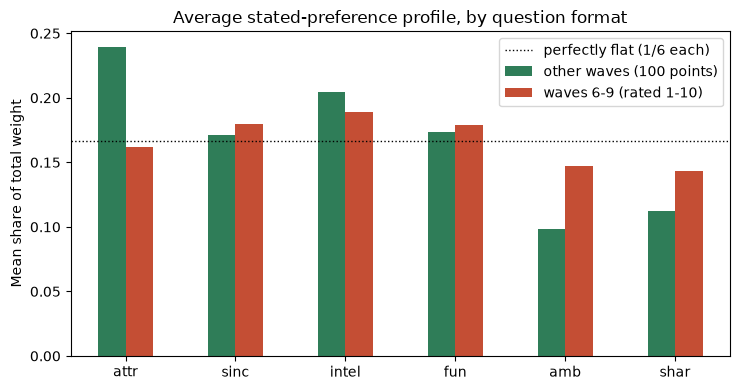

Profiles from the 100-point form are 2.7x more spread out than the
converted 1-10 profiles, measured on the identical normalised scale.

The floor effect, which is structural rather than behavioural:
  100-point waves: 20.2% of people gave at least one attribute a flat zero.
  Waves 6-9:       0.0% -- the 1-10 form has no zero, so the
                   minimum answer of 1 always leaves a positive share.


In [37]:
# Same normalised scale, two question formats: is the SHAPE of the profiles comparable?
# `stated_shares` (above) is one row per person, six weights summing to 1.
shares = stated_shares.dropna()
question_format = np.where(pref.loc[shares.index, "wave"].between(6, 9),
                           "waves 6-9 (rated 1-10)", "other waves (100 points)")

format_effect = pd.DataFrame({
    "participants":            shares.groupby(question_format).size(),
    "mean weight on attr":     shares.groupby(question_format)["attr"].mean(),
    "mean spread (std of 6)":  shares.std(axis=1).groupby(question_format).mean(),
    "mean largest weight":     shares.max(axis=1).groupby(question_format).mean(),
    "mean smallest weight":    shares.min(axis=1).groupby(question_format).mean(),
    "gave some attribute 0":   (shares == 0).any(axis=1).groupby(question_format).mean(),
})
display(format_effect.T)

# The average profile of each group, on the same axis. A flat profile sits on the 1/6 line.
fig, ax = plt.subplots(figsize=(7.5, 4))
shares.groupby(question_format).mean().T.plot(kind="bar", ax=ax, color=["#2f7d58", "#c44e34"])
ax.axhline(1 / 6, color="black", linestyle=":", linewidth=1, label="perfectly flat (1/6 each)")
ax.set_title("Average stated-preference profile, by question format")
ax.set_xlabel(""); ax.set_ylabel("Mean share of total weight")
plt.xticks(rotation=0); ax.legend()
plt.tight_layout(); plt.show()

flat_ratio = (format_effect.loc["other waves (100 points)", "mean spread (std of 6)"]
              / format_effect.loc["waves 6-9 (rated 1-10)", "mean spread (std of 6)"])
print(f"Profiles from the 100-point form are {flat_ratio:.1f}x more spread out than the")
print("converted 1-10 profiles, measured on the identical normalised scale.")
print()
print("The floor effect, which is structural rather than behavioural:")
print(f"  100-point waves: {format_effect.loc['other waves (100 points)', 'gave some attribute 0']:.1%} "
      "of people gave at least one attribute a flat zero.")
print(f"  Waves 6-9:       {format_effect.loc['waves 6-9 (rated 1-10)', 'gave some attribute 0']:.1%} "
      "-- the 1-10 form has no zero, so the")
print("                   minimum answer of 1 always leaves a positive share.")

**What to notice:** normalisation puts the two formats on one scale; it does not make them the same
measurement. On that shared scale the waves 6–9 profiles are **2.7× flatter** — mean spread across
the six weights of 0.034 against 0.091 — with a smaller top weight (0.20 vs 0.30) and a larger
bottom weight (0.12 vs 0.07). Attractiveness, the attribute with the widest range everywhere else,
draws 0.16 of the weight in waves 6–9 against 0.24 elsewhere.

The clearest single number is the last one: **20.2%** of participants on the 100-point form gave
some attribute a flat **zero**, and **0%** of waves 6–9 participants did — because they could not.
The 1–10 form has no zero, so a minimum answer of 1 still leaves a positive share. A waves 6–9
participant is unable to say "shared interests are worth nothing to me", while a fifth of everyone
else said exactly that.

This is not repairable in either direction: you cannot recover an intensity for people who only
ever allocated, and you cannot impose a trade-off on people who never made one. Shares are the
lowest common denominator, which is why we use them — with two consequences to carry forward.

1. **101 of 541 participants (19%), spanning 4 of the 21 folds, sit systematically compressed** on
   the preference scale. Any feature built on these weights — the compatibility gap in Section 15.4,
   the clustering of women in Section 15.2 — is flatter for those people, which pushes their scores
   toward the group average rather than toward a wrong value.
2. **Fold-to-fold variation on waves 6–9 is partly a questionnaire artefact**, not a modelling
   result. This is the same category of problem as `condtn` in Section 10.1, and belongs in the
   limitations for the same reason.

## 13. The leakage boundary — which features survive "before the date"?

Section 11 showed that `attr`, `fun` and `shar` separate a yes from a no sharply. There is a
catch that section did not address: **those ratings are filled in *during* the date.**

**Three independent sources agree on where the line sits**, which is worth stating because it
removes any doubt that this is our interpretation rather than the project's specification:

- `report.qmd` states that prediction happens *before the date, so only pre-date signals are
  admissible (this drives everything downstream)*, and excludes *"scorecard ratings, `dec`/`dec_o`,
  `like`, `prob`, all `_s`/`_2`/`_3` surveys"*.
- The proposal deck (slide 5) states flatly that *"features are strictly pre-date"*.
- `dataset_key_description.qmd` carries its own leakage note: *"for a model that predicts before
  the date, use only pre-date fields (identifiers, signup profile, interests, and the `_1`
  preference/self blocks, plus `pf_o_*`, `age_o`, `race_o`, `int_corr`, `samerace`). Exclude the
  scorecard block, all `_o` event ratings, and the `_s`/`_2`/`_3` surveys."*

Taken literally, the six in-date attribute ratings are on the wrong side of that line.

So Section 11 measured the signal in features the deployed model may not be allowed to see, and
**never measured the ones it is**. This section closes that gap. It splits the candidate features
into two families and measures each:

| family | examples | available before the date? |
|---|---|---|
| **A · Profile / dyadic** | `age_diff`, `same_field`, `same_goal`, `go_out_diff`, `date_diff`, `samerace`, `int_corr`, stated preference shares | **Yes** — all from the signup survey |
| **B · Behavioural (train-only)** | `selectivity`, `desirability`, `avg_attr_received` | **In principle yes**, if estimated from *other* dates in *training* waves — but see Section 15: under this project's actual protocol there are no such dates, and this whole family collapses |
| **C · In-date scorecard** | `attr … shar`, `like`, `prob` | **No** — recorded at the same moment as the decision |

Family B is the interesting case: it aggregates decisions, so it is only admissible if it is
estimated on a training subset and mapped onto held-out waves. We test below how much that
discipline costs — and then, in **Section 15**, whether the protocol on slide 5 leaves any
training history to estimate it from at all. (It does not. Read Section 13 as measuring the
*upper bound* on what a behavioural feature could ever contribute, not as a recommendation.)

This section **measures** the boundary; where the line is finally drawn belongs to the
feature-engineering step. Notebook 02 draws it here: the compatibility feature is rebuilt from
pre-date self-ratings (Section 15.4) and the behavioural family is excluded outright (Section 15).

### 13.1 Building the family-A features — what ships ready-made, and what needs a join

A detail that shapes the whole feature-engineering step: **which partner attributes are already on
the row, and which have to be joined on.** The data key's pre-date whitelist names four ready-made
partner fields — `age_o`, `race_o`, `int_corr` and, easy to miss, the **`pf_o_*` block**:

| ready-made on the row | needs a `pid` join |
|---|---|
| `age_o`, `race_o` — partner's age and race | `field_cd`, `goal`, `go_out`, `date`, `career_c` — no `_o` versions exist |
| `int_corr`, `samerace` — pair-level, precomputed | `attr3_1 … amb3_1` — the partner's self-ratings |
| **`pf_o_att … pf_o_sha` — the partner's complete stated-preference block** | |

That last row matters more than it looks. `pf_o_*` is the partner's `attr1_1 … shar1_1` copied onto
the row — exactly the input the deck's **X₂** needs ("pairwise feature vectors encoding both
people's attributes and stated preferences") and what **X₁** clusters women on. We verify below
that it really is the same data, rather than trusting the documentation.

For everything in the right-hand column we use a **map-join** (`join(..., on="pid")`) rather than
the mirror merge of Section 3. The mirror merge needs the partner's row to exist *and* point back;
the map-join needs only a non-null `pid`, so it keeps rows the merge would drop. We report the
coverage cost of each engineered feature so the imputation budget is known up front.

In [38]:
# One profile row per person, then attach it to each date row twice: once for the decider
# (on `iid`) and once for the partner (on `pid`, suffixed `_p`).
PROFILE = ["age", "field_cd", "goal", "go_out", "date", "imprace", "imprelig", "race", "career_c"]
profile = df.drop_duplicates("iid").set_index("iid")[PROFILE]

pre = df[["iid", "pid", "wave", "gender", "dec", "match", "samerace", "int_corr"]].copy()
pre = pre.join(profile, on="iid").join(profile.add_suffix("_p"), on="pid")


def same(a, b):
    """1.0 if the two codes agree, 0.0 if they differ, NaN if either side is missing."""
    return (a == b).astype("float64").where(a.notna() & b.notna())


# Dyadic content features -- leakage-free, computable for any pair before they meet.
pre["age_diff"]        = (pre["age"] - pre["age_p"]).abs()
pre["same_field"]      = same(pre["field_cd"], pre["field_cd_p"])
pre["same_goal"]       = same(pre["goal"], pre["goal_p"])
pre["same_career"]     = same(pre["career_c"], pre["career_c_p"])
pre["go_out_diff"]     = (pre["go_out"] - pre["go_out_p"]).abs()
pre["date_diff"]       = (pre["date"] - pre["date_p"]).abs()
pre["race_importance"] = pre["imprace"] * pre["samerace"]

FAMILY_A = ["age_diff", "same_field", "same_goal", "same_career", "go_out_diff", "date_diff",
            "samerace", "race_importance", "int_corr", "age", "age_p"]

coverage = pd.DataFrame({
    "non_null": pre[FAMILY_A].notna().sum(),
    "nan_fraction": pre[FAMILY_A].isna().mean(),
})
display(coverage)

print(f"Rows kept by the `pid` map-join: {pre['pid'].notna().sum():,} of {len(pre):,} "
      f"({pre['pid'].isna().sum()} rows have no `pid` at all).")
print(f"For comparison, the strict mirror merge of Section 3 keeps 8,368.")
print()
print("NOT CONSTRUCTIBLE: the feature list also suggests a religion analogue of `race_importance`.")
print("The file has `imprelig` (how much religion matters to you) but NO religion identity column")
print("and no `samerelig`, so `imprelig * samerelig` cannot be built. Only the race version exists.")

,non_null,nan_fraction
age_diff,8180,0.024
same_field,8204,0.021
same_goal,8210,0.020
same_career,8094,0.034
go_out_diff,8210,0.020
date_diff,8174,0.024
samerace,8378,0.000
race_importance,8299,0.009
int_corr,8220,0.019
age,8283,0.011


Rows kept by the `pid` map-join: 8,368 of 8,378 (10 rows have no `pid` at all).
For comparison, the strict mirror merge of Section 3 keeps 8,368.

NOT CONSTRUCTIBLE: the feature list also suggests a religion analogue of `race_importance`.
The file has `imprelig` (how much religion matters to you) but NO religion identity column
and no `samerelig`, so `imprelig * samerelig` cannot be built. Only the race version exists.


In [39]:
# Is `pf_o_*` really the partner's own stated-preference block? Verify rather than assume:
# join the partner's `attr1_1 ... shar1_1` on `pid` and compare value by value.
PF_O = ["pf_o_att", "pf_o_sin", "pf_o_int", "pf_o_fun", "pf_o_amb", "pf_o_sha"]
own_pref = df.drop_duplicates("iid").set_index("iid")[PREF1]

joined = df[["pid"]].join(own_pref.set_axis([c + "_j" for c in PF_O], axis=1), on="pid")
both = df[PF_O].notna().all(axis=1) & joined[[c + "_j" for c in PF_O]].notna().all(axis=1)
gap = np.abs(df.loc[both, PF_O].to_numpy() - joined.loc[both, [c + "_j" for c in PF_O]].to_numpy())

print(f"Rows with a complete `pf_o_*` block: {int(df[PF_O].notna().all(axis=1).sum()):,} of {len(df):,} "
      f"({df[PF_O].notna().all(axis=1).mean():.1%})")
print(f"Rows compared against the partner's own `1_1` via the join: {int(both.sum()):,}")
print(f"Maximum absolute difference: {gap.max():.4f}   (mean {gap.mean():.5f})")
print()
print("Confirmed: `pf_o_*` IS the partner's stated-preference block, already on the row.")
print("No join is needed for it -- and it is pre-date, so it is admissible under every version")
print("of the leakage rule. This is the reciprocal half of a compatibility feature: their stated")
print("weights against our attributes, alongside our weights against theirs.")

Rows with a complete `pf_o_*` block: 8,249 of 8,378 (98.5%)
Rows compared against the partner's own `1_1` via the join: 8,249
Maximum absolute difference: 0.0000   (mean 0.00000)

Confirmed: `pf_o_*` IS the partner's stated-preference block, already on the row.
No join is needed for it -- and it is pre-date, so it is admissible under every version
of the leakage rule. This is the reciprocal half of a compatibility feature: their stated
weights against our attributes, alongside our weights against theirs.


### 13.2 Do the pre-date features carry any signal?

The honest test: correlate every family-A feature with the decision, and plot it on the **same
axis** as the in-date ratings from Section 11. If the pre-date block is much weaker, we need to
know that now — it determines whether the model has anything to work with.

,corr_dec,corr_match
age_p,-0.049,-0.036
same_field,0.047,0.063
go_out_diff,-0.045,-0.064
age_diff,-0.036,-0.069
samerace,0.023,0.013
int_corr,0.019,0.031
same_career,0.017,0.027
age,0.016,-0.035
race_importance,0.011,-0.001
date_diff,0.009,0.021


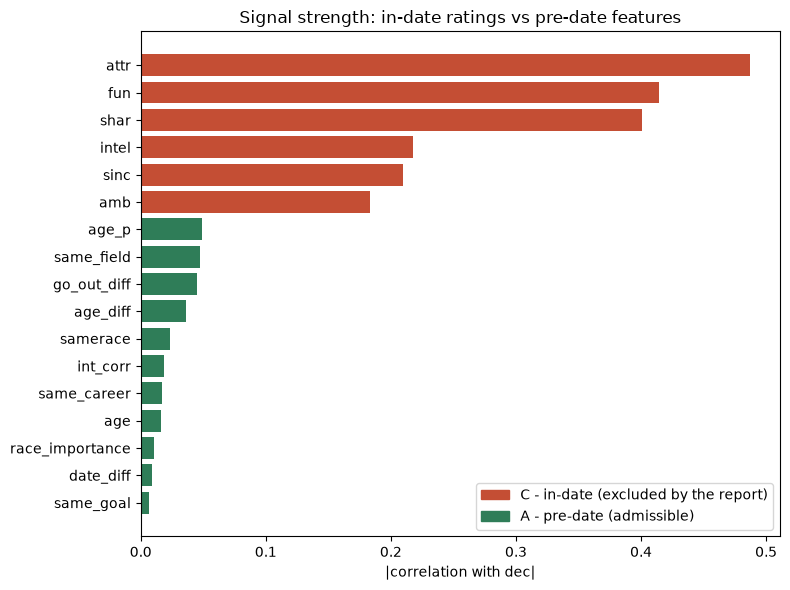

Strongest pre-date content feature: |r| = 0.049
Strongest in-date rating:           |r| = 0.487 (attr)
Every family-A content feature sits at or below |r| = 0.05. On its own, the profile block
is close to useless for predicting a decision.


In [40]:
# Correlation of each family-A feature with the one-sided decision and the mutual match.
signal_a = pd.DataFrame({
    "corr_dec":   [pre[f].corr(pre["dec"]) for f in FAMILY_A],
    "corr_match": [pre[f].corr(pre["match"]) for f in FAMILY_A],
}, index=FAMILY_A).sort_values("corr_dec", key=abs, ascending=False)
display(signal_a)

# Same axis as the in-date ratings, so the size difference is visible rather than argued.
in_date = ["attr", "fun", "shar", "intel", "sinc", "amb"]
compare = pd.concat([
    pd.Series({f: abs(df[f].corr(df["dec"])) for f in in_date}).rename("r"),
    pd.Series({f: abs(signal_a.loc[f, "corr_dec"]) for f in FAMILY_A}).rename("r"),
])
families = ["C - in-date"] * len(in_date) + ["A - pre-date"] * len(FAMILY_A)
colours = ["#c44e34" if f.startswith("C") else "#2f7d58" for f in families]

order = np.argsort(compare.values)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(np.arange(len(compare)), compare.values[order],
        color=[colours[i] for i in order])
ax.set_yticks(np.arange(len(compare))); ax.set_yticklabels(compare.index[order])
ax.set_title("Signal strength: in-date ratings vs pre-date features")
ax.set_xlabel("|correlation with dec|")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#c44e34", "#2f7d58"]]
ax.legend(handles, ["C - in-date (excluded by the report)", "A - pre-date (admissible)"],
          loc="lower right")
plt.tight_layout(); plt.show()

best_a = compare[[f in FAMILY_A for f in compare.index]].max()
print(f"Strongest pre-date content feature: |r| = {best_a:.3f}")
print(f"Strongest in-date rating:           |r| = {abs(df['attr'].corr(df['dec'])):.3f} (attr)")
print("Every family-A content feature sits at or below |r| = 0.05. On its own, the profile block")
print("is close to useless for predicting a decision.")

### 13.3 The behavioural block — strong, but only if estimated honestly

Family B is the remaining hope. Two person-level statistics:

- **selectivity** = how often *this person* says yes;
- **desirability** = how often *the partner* is said yes to.

Both aggregate decisions, so they can leak. We compute each **two ways** — naively (including the
current date in the person's own average) and **leave-one-out** (excluding it) — to show
concretely how much the naive version inflates itself. Leave-one-out is the row-level analogue of
the train-only rule; the real pipeline must go further and estimate on training *waves*.

In [41]:
# Selectivity: this person's yes-rate, with and without the current date.
g_dec = df.groupby("iid")["dec"]
sel_naive = g_dec.transform("mean")
sel_loo   = (g_dec.transform("sum") - df["dec"]) / (g_dec.transform("size") - 1)

# Desirability of the PARTNER: their received-yes rate, with and without our own vote.
# (On the partner's own rows, `dec_o` is each partner's decision about them.)
received = df.groupby("iid")["dec_o"].agg(["sum", "size"])
p_sum, p_n = df["pid"].map(received["sum"]), df["pid"].map(received["size"])
des_naive = p_sum / p_n
des_loo   = (p_sum - df["dec"]) / (p_n - 1)      # our own vote is one of the partner's `dec_o`

leak = pd.DataFrame({
    "corr_dec": [sel_naive.corr(df["dec"]), sel_loo.corr(df["dec"]),
                 des_naive.corr(df["dec"]), des_loo.corr(df["dec"])],
    "corr_match": [sel_naive.corr(df["match"]), sel_loo.corr(df["match"]),
                   des_naive.corr(df["match"]), des_loo.corr(df["match"])],
}, index=["selectivity (naive)", "selectivity (leave-one-out)",
          "partner desirability (naive)", "partner desirability (leave-one-out)"])
display(leak)

infl_s = leak.loc["selectivity (naive)", "corr_dec"] - leak.loc["selectivity (leave-one-out)", "corr_dec"]
infl_d = (leak.loc["partner desirability (naive)", "corr_dec"]
          - leak.loc["partner desirability (leave-one-out)", "corr_dec"])
print(f"Self-inclusion inflates selectivity by {infl_s:+.3f} and partner desirability by {infl_d:+.3f}")
print("correlation points. That is the leak, measured -- and it is only the row-level version.")
print("Estimating across whole waves, as the CV protocol requires, will cost more again.")

,corr_dec,corr_match
selectivity (naive),0.509,0.178
selectivity (leave-one-out),0.402,0.118
partner desirability (naive),0.475,0.207
partner desirability (leave-one-out),0.356,0.141


Self-inclusion inflates selectivity by +0.107 and partner desirability by +0.119
correlation points. That is the leak, measured -- and it is only the row-level version.
Estimating across whole waves, as the CV protocol requires, will cost more again.


In [42]:
# How stable is a person-level rate estimated from only a handful of dates?
# Split-half reliability: estimate desirability on a random half of each person's dates,
# and again on the other half. A stable estimator agrees with itself.
half = pd.Series(rng.random(len(df)) < 0.5, index=df.index)
h_a = df[half].groupby("iid")["dec_o"].agg(["sum", "size"])
h_b = df[~half].groupby("iid")["dec_o"].agg(["sum", "size"])
halves = h_a.join(h_b, lsuffix="_a", rsuffix="_b").dropna()
halves = halves[(halves["size_a"] >= 2) & (halves["size_b"] >= 2)]

prior = df["dec_o"].mean()          # global training mean -- also the cold-start fallback


def shrink(s, n, m):
    """Rate shrunk toward the global mean; m = strength (m=0 is the raw rate)."""
    return (s + m * prior) / (n + m)


rows = []
for m in [0, 1, 2, 5, 10, 20, 50, 100, 200]:   # past the optimum, so the turn is visible
    a = shrink(halves["sum_a"], halves["size_a"], m)
    b = shrink(halves["sum_b"], halves["size_b"], m)
    rows.append({"shrinkage_m": m, "split_half_corr": a.corr(b)})
reliability = pd.DataFrame(rows).set_index("shrinkage_m")
display(reliability)

n_dates = df.groupby("iid").size()
print(f"Dates per person: min {n_dates.min()}, median {int(n_dates.median())}, max {n_dates.max()}")
print(f"{(n_dates <= 10).mean():.1%} of participants have 10 dates or fewer, so their raw rate")
print("moves by at least 10 percentage points with a single flipped decision.")
best_m = reliability["split_half_corr"].idxmax()
print(f"\nBest split-half agreement at m = {best_m} "
      f"({reliability['split_half_corr'].max():.3f}, versus "
      f"{reliability.loc[0, 'split_half_corr']:.3f} for the raw rate) -- an interior\n"
      f"optimum, not a grid edge: agreement falls again for m = 50 and above, where the\n"
      f"estimate is pulled so hard toward the mean that it stops distinguishing people.")
print(f"Global mean used as the shrinkage target and cold-start fallback: {prior:.3f}")

,split_half_corr
shrinkage_m,
0,0.545
1,0.568
2,0.581
5,0.598
10,0.606
20,0.608
50,0.606
100,0.604
200,0.602


Dates per person: min 5, median 16, max 22
32.5% of participants have 10 dates or fewer, so their raw rate
moves by at least 10 percentage points with a single flipped decision.

Best split-half agreement at m = 20 (0.608, versus 0.545 for the raw rate) -- an interior
optimum, not a grid edge: agreement falls again for m = 50 and above, where the
estimate is pulled so hard toward the mean that it stops distinguishing people.
Global mean used as the shrinkage target and cold-start fallback: 0.420


**What to notice:** this is the single most consequential result in the notebook for the next step.

**The profile block is nearly empty of signal.** Every family-A feature sits at or below
|r| = 0.05 against `dec` — the partner's age −0.05, `same_field` 0.05, `go_out_diff` −0.05,
`age_diff` −0.04, `samerace` 0.02, `int_corr` 0.02, `same_career` 0.02, `race_importance` 0.01,
`date_diff` 0.01, `same_goal` −0.01. These are not useless (a model
can combine weak features, and they matter for interpretability and fairness analysis), but no
combination of them will carry a recommender on its own.

**The behavioural block is where the signal lives.** Leave-one-out selectivity correlates with
`dec` at ≈ 0.40 and partner desirability at ≈ 0.36 — an order of magnitude above anything in
family A, and comparable to the in-date ratings the report excludes. A pre-date recommender is
essentially a reputation model with profile features as a garnish.

**Which makes the leakage discipline the whole ballgame, not a formality.** Including the current
date in a person's own average inflates the correlation by roughly 0.11 and 0.12 points. That is
the *row-level* leak alone; estimating across waves will cost more. Any behavioural feature must
be fitted on training waves and mapped onto held-out ones — exactly the
`add_behavioural_features(train_df, apply_df)` shape the feature-engineering brief specifies.

**And rates on 5–10 dates need shrinking.** A third of participants have 10 dates or fewer, where
one flipped decision moves the raw rate by 10 percentage points. Shrinking toward the global mean
lifts split-half agreement from 0.545 to 0.608 at an *interior* optimum of m ≈ 20 (it falls again
beyond that, where every estimate collapses toward the mean), and the same global mean is the
natural cold-start value
for a participant who never appears in the training waves. This is the same reasoning behind the
Wilson lower bound the proposal already suggests for the popularity baseline.

**One caveat that Section 15 turns into a correction.** Everything above measures the behavioural
features on data where a person's *other* dates are available. Under the leave-one-wave-out
protocol on slide 5 they are not: participants appear in exactly one wave, so a held-out
participant has no training history at all. Section 15 shows what that does to this section's
conclusion.


## 14. Variable scales and ranges — the normalisation brief

The next notebook normalises the variables. Normalising blindly is how quiet bugs get in: a column
documented as 1–10 that actually contains a 14 will silently stretch a min-max scaler, and a
categorical code stored as a float will be standardised as if the distance from "law" to "medicine"
were meaningful.

So before scaling anything we audit what is actually in the file: the nominal range, the observed
range, how many values fall outside it, and how many distinct levels the categoricals have.

In [43]:
# Every column group the feature-engineering step touches, with its documented range.
INTERESTS = ["sports", "tvsports", "exercise", "dining", "museums", "art", "hiking", "gaming",
             "clubbing", "reading", "tv", "theater", "movies", "concerts", "music", "shopping", "yoga"]

GROUPS = {
    "in-date ratings (1-10)":      (["attr", "sinc", "intel", "fun", "amb", "shar", "like", "prob"], 1, 10),
    "self-ratings 3_1 (1-10)":     (["attr3_1", "sinc3_1", "intel3_1", "fun3_1", "amb3_1"], 1, 10),
    "partner's ratings (1-10)":    (["attr_o", "sinc_o", "intel_o", "fun_o", "amb_o", "shar_o", "like_o"], 1, 10),
    "interests (1-10)":            (INTERESTS, 1, 10),
    "importance (1-10)":           (["imprace", "imprelig"], 1, 10),
    "frequency ordinals (1-7)":    (["go_out", "date"], 1, 7),
    "stated preferences (~100)":   (["attr1_1", "sinc1_1", "intel1_1", "fun1_1", "amb1_1", "shar1_1"], 0, 100),
    "interest correlation (-1,1)": (["int_corr"], -1, 1),
    "age (years)":                 (["age", "age_o"], 18, 60),
}

rows = []
for group, (cols, lo, hi) in GROUPS.items():
    block = df[cols]
    outside = ((block < lo) | (block > hi)).sum().sum()
    rows.append({
        "group": group, "n_cols": len(cols), "nominal": f"{lo} to {hi}",
        "observed_min": block.min().min(), "observed_max": block.max().max(),
        "n_values_outside": int(outside), "max_nan_frac": block.isna().mean().max(),
    })
scale_audit = pd.DataFrame(rows).set_index("group")
display(scale_audit)

# Categoricals: codes, not magnitudes. These must be one-hot encoded, never scaled.
CATEGORICAL = ["field_cd", "career_c", "goal", "race", "gender", "samerace"]
cat_audit = pd.DataFrame({
    "n_levels": [int(df[c].nunique()) for c in CATEGORICAL],
    "min_code": [df[c].min() for c in CATEGORICAL],
    "max_code": [df[c].max() for c in CATEGORICAL],
    "nan_frac": [df[c].isna().mean() for c in CATEGORICAL],
}, index=CATEGORICAL)
display(cat_audit)

,n_cols,nominal,observed_min,observed_max,n_values_outside,max_nan_frac
group,,,,,,
in-date ratings (1-10),8,1 to 10,0.000,10.000,157,0.127
self-ratings 3_1 (1-10),5,1 to 10,2.000,10.000,0,0.013
partner's ratings (1-10),7,1 to 10,0.000,11.000,110,0.128
interests (1-10),17,1 to 10,0.000,14.000,350,0.009
importance (1-10),2,1 to 10,0.000,10.000,8,0.009
frequency ordinals (1-7),2,1 to 7,1.000,7.000,0,0.012
stated preferences (~100),6,0 to 100,0.000,100.000,0,0.014
"interest correlation (-1,1)",1,-1 to 1,-0.830,0.910,0,0.019
age (years),2,18 to 60,18.000,55.000,0,0.012


,n_levels,min_code,max_code,nan_frac
field_cd,18,1.000,18.000,0.010
career_c,17,1.000,17.000,0.016
goal,6,1.000,6.000,0.009
race,5,1.000,6.000,0.008
gender,2,0.000,1.000,0.000
samerace,2,0.000,1.000,0.000


### 14.1 Out-of-range values — what the Section 11 filter was hiding

The table above shows the documented ranges are not respected everywhere. Section 11 quietly
dropped these with a `between(0, 10)` guard; here we count them explicitly, because the
feature-engineering step needs a stated rule rather than an inherited habit.

In [44]:
# Exactly which ratings fall outside their documented 1-10 range, and how often.
RATING_COLS = ["attr", "sinc", "intel", "fun", "amb", "shar", "like", "prob",
               "attr_o", "sinc_o", "intel_o", "fun_o", "amb_o", "shar_o", "like_o"]

rows = []
for c in RATING_COLS + INTERESTS:
    s = df[c]
    below, above = int((s < 1).sum()), int((s > 10).sum())
    if below or above:
        rows.append({"column": c, "observed_min": s.min(), "observed_max": s.max(),
                     "n_below_1": below, "n_above_10": above,
                     "pct_of_rows": (below + above) / len(df)})
out_of_range = pd.DataFrame(rows).set_index("column").sort_values("pct_of_rows", ascending=False)
display(out_of_range)

n_bad = int(out_of_range["n_below_1"].sum() + out_of_range["n_above_10"].sum())
print(f"{n_bad} values across {len(out_of_range)} columns fall outside the documented 1-10 range "
      f"({n_bad / (len(df) * len(RATING_COLS + INTERESTS)):.3%} of all rating cells).")
print()

# The interests are the clearest case: a handful of participants used a scale of their own.
people_int = df.drop_duplicates("iid").set_index("iid")[INTERESTS]
print(f"Participants with an interest rating above 10: {int(people_int.gt(10).any(axis=1).sum())} "
      f"of {len(people_int)} (values reach {people_int.max().max():.0f}).")
print(f"Participants with an interest rating of 0:     {int(people_int.eq(0).any(axis=1).sum())}")
print()
worst = out_of_range["pct_of_rows"].idxmax()
print("RECOMMENDATION for feature engineering: clip every 1-10 rating and interest column to")
print(f"[1, 10] before scaling. The affected counts are small -- the worst column, `{worst}`,")
print(f"touches {out_of_range.loc[worst, 'pct_of_rows']:.1%} of rows -- so clipping costs almost")
print("nothing. But leaving a 13 or a 14 in place would stretch a min-max scaler across the")
print("whole column and quietly distort every other value in it.")

,observed_min,observed_max,n_below_1,n_above_10,pct_of_rows
column,,,,,
gaming,0.000,14.000,59,78,0.016
shar,0.000,10.000,59,0,0.007
shar_o,0.000,10.000,59,0,0.007
reading,1.000,13.000,0,51,0.006
prob,0.000,10.000,49,0,0.006
yoga,0.000,10.000,36,0,0.004
art,0.000,10.000,18,0,0.002
museums,0.000,10.000,18,0,0.002
clubbing,0.000,10.000,18,0,0.002


617 values across 25 columns fall outside the documented 1-10 range (0.230% of all rating cells).



Participants with an interest rating above 10: 8 of 551 (values reach 14).
Participants with an interest rating of 0:     6

RECOMMENDATION for feature engineering: clip every 1-10 rating and interest column to
[1, 10] before scaling. The affected counts are small -- the worst column, `gaming`,
touches 1.6% of rows -- so clipping costs almost
nothing. But leaving a 13 or a 14 in place would stretch a min-max scaler across the
whole column and quietly distort every other value in it.


**What to notice — and the brief this hands to the normalisation step.**

The documented ranges are *mostly* respected, but not entirely. 617 cells across 25 columns fall
outside 1–10 — 0.23% of all rating cells. Two kinds of violation:

- **Values below 1**, mostly zeros: `shar`/`shar_o` (59 rows each), `prob` (49), `yoga` (36),
  and a scatter of others.
- **Values above 10**, which are the dangerous ones for a min-max scaler: `gaming` reaches **14**
  and `reading` reaches **13** (the worst column, `gaming`, touches 1.6% of rows), while
  `fun_o` reaches 11.0 and `attr_o` reaches 10.5. At participant level this is just **8 people
  of 551** who rated an interest above 10 — a few individuals using a scale of their own.

None of it is common enough to matter statistically; all of it is enough to distort a min-max
scaler, which keys on the extremes rather than the mass.

The concrete plan for the next notebook:

| column group | treatment |
|---|---|
| Ratings `attr … shar`, `like`, `prob` and their `_o` versions | **clip to [1, 10]**, then min-max to [0, 1] |
| 17 interests | **clip to [1, 10]** — `gaming` and `reading` need it — then min-max to [0, 1] |
| `imprace`, `imprelig` (1–10, 8 zeros); `go_out`, `date` (1–7, clean) | **clip**, then min-max to [0, 1] on the *documented* range, so the scale means the same thing in every fold |
| Stated preferences `attr1_1 … shar1_1` | normalise each participant's six weights to **sum to 1** (Section 12) — already scale-free, do not scale again |
| `age`, `age_diff`, `go_out_diff`, `date_diff` | standardise (z-score) — unbounded and roughly symmetric |
| `int_corr` | leave as is — already a correlation on [−1, 1] |
| `field_cd` (18), `career_c` (17), `goal` (6), `race` (5 of 6 codes present — no Native American) | **one-hot encode**, never scale: these are codes, and the numeric distance between them is meaningless |
| `samerace`, `gender`, `same_field`, `same_goal` | leave as 0/1 indicators |
| Behavioural rates (`selectivity`, `desirability`, …) | already on [0, 1]; shrink toward the training mean (Section 13.3) rather than rescale |

One rule ties this to the rest of the project: **fit every scaler on the training waves only and
apply it to the held-out wave**, exactly as the behavioural features are estimated. A min-max
scaler fitted on the full table has seen the held-out fold's extremes, which is the same leak in a
quieter form.


## 15. Does the protocol allow the features we want? — the cold-start collision

Slide 5 states the protocol in one line: *"Participants never appear in two waves, so every test
fold is a genuine cold start — no identity leakage."*

That sentence is doing far more work than it looks. Section 13 concluded that the behavioural
features — `selectivity`, `desirability`, `avg_attr_received` — are the only pre-date signals with
real strength (|r| ≈ 0.36–0.40, against |r| ≤ 0.05 for everything else). Those features are
estimated from a person's *other* dates in the *training* waves.

But if a participant appears in exactly one wave, and that wave is held out, then that person has
**no dates in the training set at all**. Every behavioural feature falls back to its cold-start
default. We verify this rather than assume it, because if it holds, Section 13's conclusion needs
correcting and the popularity baseline on slide 4 needs re-specifying.

In [45]:
# For each of the 21 folds: how many held-out participants have ANY history in the training waves?
rows = []
for w in sorted(df["wave"].unique()):
    test_people  = set(df.loc[df["wave"] == w, "iid"])
    train_people = set(df.loc[df["wave"] != w, "iid"])
    test_partners = set(df.loc[df["wave"] == w, "pid"].dropna())
    rows.append({
        "wave": w,
        "test_participants": len(test_people),
        "seen_in_training": len(test_people & train_people),
        "partners_seen_in_training": len(test_partners & train_people),
    })
cold_start = pd.DataFrame(rows).set_index("wave")
display(cold_start)

total_seen = int(cold_start["seen_in_training"].sum())
print(f"Held-out participants with ANY training history, summed over all 21 folds: {total_seen}")
print(f"Held-out partners with any training history:                               "
      f"{int(cold_start['partners_seen_in_training'].sum())}")
print()
print("The slide is exactly right, and the consequence is total: EVERY test row gets the")
print("cold-start fallback for EVERY behavioural feature. A fallback is a constant, and a constant")
print("cannot reorder a ranked list -- so within a held-out wave those features contribute")
print("precisely nothing. Their measured strength in Section 13 is unreachable under this protocol.")

,test_participants,seen_in_training,partners_seen_in_training
wave,,,
1,20,0,0
2,35,0,0
3,20,0,0
4,36,0,0
5,19,0,0
6,10,0,0
7,32,0,0
8,20,0,0
9,40,0,0


Held-out participants with ANY training history, summed over all 21 folds: 0
Held-out partners with any training history:                               0

The slide is exactly right, and the consequence is total: EVERY test row gets the
cold-start fallback for EVERY behavioural feature. A fallback is a constant, and a constant
cannot reorder a ranked list -- so within a held-out wave those features contribute
precisely nothing. Their measured strength in Section 13 is unreachable under this protocol.


### 15.1 What this breaks — including the baseline

Two consequences, one for the features and one for the baseline on slide 4.

**The behavioural family is not merely weakened, it is unavailable.** This is a correction to
Section 13, which measured those features on data where a person's other dates were present. That
measurement is still a valid *upper bound* — it says what a reputation feature could contribute if
history existed — but it is not a recommendation, because under leave-one-wave-out no history
does. `add_behavioural_features(train_df, apply_df)` will return the global mean for 100% of rows
on every fold.

**The popularity baseline as worded is not computable from training data.** Slide 4 defines **Z**
as *"Desirability score — each partner ranked by how often they received a 'yes' from others met."*
For a held-out wave, nobody has received a "yes" from anyone in the training data. There are three
honest ways out, and the choice must be stated in the report:

| option | what it means | verdict |
|---|---|---|
| **Within-fold desirability** | Compute each test partner's received-yes rate from the *test wave's own* decisions | Ranks candidates using the labels being predicted. Legitimate only if declared as a deliberately **optimistic / transductive** reference — an upper bound on what popularity could do, not a fair baseline |
| **Predicted desirability** | Train a model on the training waves that predicts desirability from *profile* features, then apply it to cold test participants | Genuinely cold-start-safe and still "global, not personalised", so it keeps the baseline's character. **Recommended** |
| **Global constant** | Give every candidate the same score | Truly leakage-free, but it makes the baseline a random shuffle and the comparison meaningless |

The middle option preserves everything slide 4 wants from **Z** — global, non-personalised, the
"most-popular" null hypothesis — while surviving the cold start. It is a small addition to the
baseline's definition, not a change of method.

### 15.2 What still works — and does X₁'s core assumption hold?

The cold start does not rule out the two methods on slide 4, and the reason is worth stating
precisely: **X₁ and X₂ generalise through *features*, not through identity.** A cold participant
can still be assigned to a cluster from their signup profile (X₁), or encoded as a feature vector
(X₂), and inherit what the training waves learned about people *like* them. That is exactly why
those two methods were the right choice for this dataset — an identity-embedding recommender
(plain matrix factorisation over user ids) would have been unusable here.

But X₁ rests on an assumption nobody has tested: that **cluster-pair match rates learned on
training waves still hold on a held-out wave**. Slide 5 already names this as a risk ("cluster-pair
match rates will be noisier than in the original settings due to smaller dataset"). We can measure
it now rather than discover it in the results table.

The test below implements slide 4's design directly: men clustered by their **attributes**
(self-ratings, `attr3_1 … amb3_1` — pre-date and available at signup), women clustered by their
**stated preferences** (`attr1_1 … shar1_1` as shares). We then score a held-out wave using only
cluster-pair yes-rates fitted on the other 20 waves, and ask whether that beats a coin flip.

In [46]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

# Slide 4's gender-asymmetric design, built only from pre-date signup data.
SELF3 = ["attr3_1", "sinc3_1", "intel3_1", "fun3_1", "amb3_1"]   # how I rate MYSELF
K = 4

men   = people_pref[people_pref["gender"] == 1]
women = people_pref[people_pref["gender"] == 0]

X_men   = men[SELF3]
X_women = women[PREF1].div(women[PREF1].sum(axis=1), axis=0)      # preference SHARES
print(f"Men with a complete self-rating block:     {int(X_men.notna().all(axis=1).sum())} / {len(men)}")
print(f"Women with a complete preference block:    {int(X_women.notna().all(axis=1).sum())} / {len(women)}")

X_men   = X_men.fillna(X_men.median())
X_women = X_women.fillna(X_women.median())

cl_men   = pd.Series(KMeans(K, random_state=SEED, n_init=10)
                     .fit_predict(StandardScaler().fit_transform(X_men)), index=X_men.index)
cl_women = pd.Series(KMeans(K, random_state=SEED, n_init=10)
                     .fit_predict(StandardScaler().fit_transform(X_women)), index=X_women.index)
cluster_of = pd.concat([cl_men, cl_women])

# One cell per (decider gender, decider cluster, partner cluster).
cl = df[["iid", "pid", "wave", "gender", "dec", "match"]].dropna(subset=["pid"]).copy()
cl["cl_self"] = cl["iid"].map(cluster_of)
cl["cl_part"] = cl["pid"].map(cluster_of)
cl = cl.dropna(subset=["cl_self", "cl_part"])
cl["pair"] = (cl["gender"].astype(int).astype(str) + "_"
              + cl["cl_self"].astype(int).astype(str) + "->"
              + cl["cl_part"].astype(int).astype(str))

pair_rates = cl.groupby("pair")["dec"].agg(["mean", "size"])
print(f"\nCluster-pair cells: {cl['pair'].nunique()} over {len(cl):,} dates")
print(f"Yes-rate across cells ranges {pair_rates['mean'].min():.3f} to {pair_rates['mean'].max():.3f} "
      f"(global {cl['dec'].mean():.3f}) -- so the cells do differ.")

# THE test: fit cluster-pair rates on 20 waves, score the 21st. AUC 0.5 == no signal.
aucs = []
for w in sorted(cl["wave"].unique()):
    tr, te = cl[cl["wave"] != w], cl[cl["wave"] == w]
    if te["dec"].nunique() < 2:
        continue
    rate = tr.groupby("pair")["dec"].mean()
    pred = te["pair"].map(rate).fillna(tr["dec"].mean())      # unseen cell -> global fallback
    aucs.append(roc_auc_score(te["dec"], pred))

aucs = np.array(aucs)
print(f"\nLeave-one-wave-out AUC of the cluster-pair rate alone: {aucs.mean():.3f} +/- {aucs.std():.3f}")
print(f"Folds above chance: {(aucs > 0.5).sum()} of {len(aucs)}   "
      f"(range {aucs.min():.3f} to {aucs.max():.3f})")

Men with a complete self-rating block:     274 / 277
Women with a complete preference block:    268 / 274



Cluster-pair cells: 32 over 8,368 dates
Yes-rate across cells ranges 0.197 to 0.525 (global 0.420) -- so the cells do differ.



Leave-one-wave-out AUC of the cluster-pair rate alone: 0.553 +/- 0.084
Folds above chance: 14 of 21   (range 0.413 to 0.704)


### 15.3 How much is actually achievable under the real protocol?

The cluster-pair rate is one feature. Before committing to the proposal's targets it is worth
knowing what the *whole* strictly-pre-date feature set can do under the exact protocol on slide 5
— 21 folds, cold start, no in-date ratings. This is not a model we are proposing; it is a
feasibility probe, deliberately generous (a gradient-boosted tree with every pre-date feature we
have), to establish the ceiling the real methods are aiming at.

It also builds the **compatibility-gap feature** in its cold-start-safe form — see 15.4 below.

In [47]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Pre-date profile block for both sides of each date.
PROF = ["age", "field_cd", "goal", "go_out", "date", "imprace", "imprelig", "race", "career_c"]
signup = people_pref[PROF + SELF3 + PREF1]

fe = df[["iid", "pid", "wave", "gender", "dec", "match", "samerace", "int_corr"]].dropna(subset=["pid"]).copy()
fe = fe.join(signup, on="iid").join(signup.add_suffix("_p"), on="pid")
fe["age_diff"] = (fe["age"] - fe["age_p"]).abs()

# COMPATIBILITY GAP, cold-start-safe: my stated preference SHARES dotted with the partner's
# SELF-rated attributes. Both come from the signup survey, so both exist for an unseen person.
w_share = fe[PREF1[:5]].div(fe[PREF1].sum(axis=1), axis=0)          # attr..amb, renormalised
fe["compat_gap"] = (w_share.to_numpy() * fe[[c + "_p" for c in SELF3]].to_numpy()).sum(axis=1)

FEATURES = (["age_diff", "samerace", "int_corr", "compat_gap", "age", "age_p", "gender"]
            + ["field_cd", "goal", "go_out", "date", "imprace", "race", "career_c"]
            + ["field_cd_p", "goal_p", "go_out_p", "date_p", "race_p", "career_c_p"]
            + SELF3 + [c + "_p" for c in SELF3] + PREF1)

results = {}
for target in ["dec", "match"]:
    fold_auc = []
    for w in sorted(fe["wave"].unique()):
        tr, te = fe["wave"] != w, fe["wave"] == w
        if fe.loc[te, target].nunique() < 2:
            continue
        model = HistGradientBoostingClassifier(random_state=SEED, max_iter=200, learning_rate=0.06)
        model.fit(fe.loc[tr, FEATURES], fe.loc[tr, target])
        fold_auc.append(roc_auc_score(fe.loc[te, target],
                                      model.predict_proba(fe.loc[te, FEATURES])[:, 1]))
    results[target] = np.array(fold_auc)

ceiling = pd.DataFrame({
    "mean_AUC": {k: v.mean() for k, v in results.items()},
    "std_AUC":  {k: v.std() for k, v in results.items()},
    "folds_above_chance": {k: f"{(v > 0.5).sum()} / {len(v)}" for k, v in results.items()},
})
display(ceiling)

print("Strictly pre-date features, real leave-one-wave-out protocol, genuine cold start.")
print("AUC 0.5 would mean the pre-date data says nothing at all about who says yes to whom.")

,mean_AUC,std_AUC,folds_above_chance
dec,0.588,0.057,19 / 21
match,0.561,0.084,17 / 21


Strictly pre-date features, real leave-one-wave-out protocol, genuine cold start.
AUC 0.5 would mean the pre-date data says nothing at all about who says yes to whom.


### 15.4 The compatibility-gap feature needs a pre-date stand-in

Slide 1 defines the compatibility-gap features as *"distance between each person's stated
preferences and the partner's observed attribute ratings"*. Read literally, "observed attribute
ratings" means the ratings the partner **received during the date** — which fails slide 5's own
"features are strictly pre-date" rule twice over: they are in-date (family C of Section 13), and
for a cold-start partner they do not exist in the training data either.

The dataset does contain a pre-date substitute, and it is a good one: the **`3_1` self-rating
block**, where each participant rates their own attractiveness, sincerity, intelligence, fun and
ambition at signup. Coverage is excellent — 542 of 551 participants (98.4%), present in all 21
waves — and every value is available before anyone meets anyone. The feasibility probe above uses
exactly this form.

One limitation to design around: the self-rating block has **five** attributes, not six. There is
no `shar3_1` — nobody self-rates their "shared interests", which is a property of a pair rather
than a person. So the compatibility gap is 5-dimensional, and the sixth stated weight (`shar1_1`)
has to be either dropped from the dot product or paired with `int_corr`, which is the natural
pre-date proxy for shared interests. We renormalise the five remaining weights so the score stays
comparable across people.

**What to notice — the protocol constrains the method more than the data does.**

**The cold start is complete, not partial.** Across all 21 folds, **zero** held-out participants
and **zero** held-out partners have any history in the training waves. This is not a limitation to
mitigate; it is a structural property of a dataset where each person attends exactly one event.

**Two things in the proposal need adjusting because of it**, both small and both better fixed now
than in the results table:

1. Section 13's behavioural features cannot be used as model inputs. Their measured strength is an
   upper bound on a feature the protocol does not permit.
2. Baseline **Z** must be re-specified — preferably as *predicted* desirability from profile
   features, which keeps it global and non-personalised while surviving the cold start.

**The two proposed methods survive, and X₁'s assumption holds — weakly.** Cluster-pair yes-rates
fitted on 20 waves do carry information about the 21st, above chance but with wide fold-to-fold
variation. That is precisely the risk slide 5 already names, now quantified rather than
anticipated: the signal is real, and it is thin.

**The achievable ceiling is modest, and worth knowing before results day.** A generously-specified
gradient-boosted model on every strictly-pre-date feature clears chance on both targets under the
real protocol, but not by a wide margin. Two implications for the write-up: the improvement over a
popularity baseline will be measured in small increments, so **reporting standard deviation across
the 21 folds is essential** (Section 10 said the same for a different reason); and predicting the
symmetric `match` is harder than predicting one direction, which is an argument *for* slide 4's
design of modelling P(A→B) directionally and combining with a harmonic mean rather than fitting
`match` head-on.


## 16. Key takeaways

**About the structure of the data**

1. **We know who dated whom and where.** `(iid, pid)` identifies the pair; `wave` identifies the session.
   Every date stays inside one wave, so a wave-level split is clean and leakage-free.
2. **Matches are rare (~16.5%)**, and the yes-rate differs sharply by gender (men 47.4%, women 36.5%).
   The positive class is small, so we evaluate with ranking / minority-class metrics, not accuracy.
3. **Candidate sets are short (~10–20 partners).** The deck cuts at **@3** (NDCG@3, Precision@3,
   Coverage@3) and adds **MRR**, which is uncut and still sees reordering below rank 3. With a
   median of 2 matches per person, Precision@3 is capped at 2/3 for half the users.
4. **The columns we need are well populated, and more partner data ships ready-made than we first
   thought.** Ids, decisions, the match label and the six attribute ratings have little missing data.
   On the partner side the row already carries `age_o`, `race_o`, `int_corr`, `samerace` **and the
   `pf_o_*` block — the partner's complete stated-preference vector** (98.5% coverage, verified
   identical to their own `attr1_1 … shar1_1`). Only `field_cd`, `goal`, `go_out`, `date`,
   `career_c` and the `3_1` self-ratings need a `pid` map-join (Section 13.1), which costs the 10
   rows with no `pid`. Four pre-date profile columns are excluded on missingness instead: `expnum`
   (77%), `mn_sat` (63%), `tuition` (58%), `income` (49%) — see Section 7.1.
5. **The documented wave 6–9 preference-scale problem is half real, but coverage matters more**
   (Sections 12 and 13). For `attr1_1 … shar1_1` — the block we use — waves 6–9 have **already
   been converted** from 1–10 to 100-point shares, so all 21 waves are comparable. The raw 1–10
   scale does survive in `*4_1`, `*4_2`, `*4_3` (waves 6–9) and in `*1_s` (waves **18–20**, which
   the data key does not flag). But the binding constraint on those blocks is **wave coverage, not
   scale**: `4_1` does not exist for waves 1–5 at all (416/551 participants, 75.5%) and `1_s` is
   missing for waves 1–5 and 21, so a feature built on either would be entirely absent from
   several CV folds. `1_1` is the only preference block covering all 21 waves (541/551, 98.2%) —
   which is why it is the one we use. We still normalise it to shares, since the per-wave totals
   range from 90 to 148. But normalising equalises the *scale*, not the *question* (Section 12.1):
   waves 6–9 answered a 1–10 rating rather than a 100-point allocation, and their profiles are
   **2.7× flatter** as a result, with 0% of them able to give an attribute a zero against 20.2%
   elsewhere. That is 19% of participants and 4 of the 21 folds, and it is a limitation to report
   rather than a defect to fix.

**About the population**

6. **The sample is strongly skewed towards European/Caucasian participants**, and the smallest race
   groups hold only a couple of dozen people. A per-race fairness metric would rest on cells too thin to
   trust, which is why our beyond-accuracy fairness metric is **gender**-exposure. Race stays useful as a
   *feature* (`samerace`, `imprace`), and the skew belongs in the ecological-validity limitation.
   Note that the religion analogue is **not constructible**: the file has `imprelig` but no religion
   identity column, so there is no `samerelig` to interact it with.

**About the baseline we have to beat**

7. **Desirability is unequally distributed**, though less dramatically than the raw Gini of 0.363
   suggests: unequal candidate-set sizes alone would account for 0.186, and the size-free Gini of the
   desirability rate is **0.323**. A minority still absorb a disproportionate share of all "yes" votes
   and ~4% receive none. That inequality is exactly what a popularity ranker exploits — so the baseline
   is not trivial, and it is also why **Coverage@3** is the beyond-accuracy metric on slide 5:
   accuracy alone would hide the filter-bubble failure mode.

**About whether we can evaluate at all**

8. **A sizeable minority of users have no relevant item** (18.0% no match, 5.6% no yes given). Their MRR
   is undefined and their NDCG is convention-dependent. The evaluator must explicitly choose to *skip* or
   *zero-score* these users, and the write-up must say which — the two are not comparable.
9. **The 21 folds are not equivalent**: the per-wave match rate runs from 8.3% (wave 18) to 31.0%
   (wave 1), a **3.7× spread**. Reporting mean **and standard deviation** across folds is essential, not
   decorative. No wave needs dropping, but waves 18 and 6 (12 and 10 participants) will be noisy.

10. **One of the 21 folds' differences is by design, not noise.** The data key documents `condtn`
   — 1 = limited choice, 2 = extensive choice — a **designed manipulation**, constant within each
   wave and therefore confounded with the CV split unit. Limited-choice waves run a 46.0% yes-rate
   and 20.2% match rate against 41.2% and 15.7%; the condition explains R² ≈ 0.11 of the per-wave
   match-rate variance and correlates **+0.88** with candidate-set size — which is how the
   manipulation was operationalised. So fold difficulty is partly structural, and Precision@3 and
   Coverage@3 are partly determined by which arm of the experiment a fold belongs to. `condtn`
   cannot itself be a ranking feature: it is constant within a wave, so it reorders nothing.

**About the features**

11. **The strongest signals are in-date, and the report excludes them.** `attr` (r ≈ 0.49), `fun`
    (0.41) and `shar` (0.40) dominate the decision, with `like` (0.51) and `prob` (0.31) near-restatements
    of it. But all of these are recorded *during* the date, and the proposal admits only pre-date
    signals (Section 13). They stay valuable as diagnostics and as the motivation for the
    compatibility-gap feature, but they cannot enter the model — slide 5 rules them out, and
    Section 15 shows they are unavailable for a cold-start partner in any case.
12. **The pre-date profile block is nearly empty of signal.** Every dyadic content feature sits at or
    below |r| = 0.05 against `dec`: partner's age −0.05, `same_field` 0.05, `go_out_diff` −0.05,
    `age_diff` −0.04, `samerace` 0.02, `int_corr` 0.02, `same_career` 0.02, `race_importance`
    0.01, `date_diff` 0.01, `same_goal` −0.01. `int_corr` in
    particular is far weaker than its billing as a ready-made compatibility feature suggests. Useful for
    interpretability and fairness analysis; not enough to carry a recommender.
13. **The behavioural features look like the model's real input — and the protocol forbids them.**
    Leave-one-out selectivity correlates with `dec` at ≈ 0.40 and partner desirability at ≈ 0.36, an
    order of magnitude above the profile block. But leave-one-wave-out CV over a dataset where each
    person attends exactly one event is a **total cold start**: 0 of 551 held-out participants have
    any training history (Section 15). Those features are constant at test time and cannot rank
    anything. Their strength is an upper bound on a feature we are not allowed to use.
14. **The popularity baseline needs re-specifying, for the same reason.** Slide 4 defines **Z** as
    "how often they received a yes from others met" — unknowable for a held-out participant with no
    training history. We recommend **predicted desirability** from profile features: still global and
    non-personalised, but computable. A within-fold version is acceptable only if labelled as a
    deliberately optimistic upper bound, since it reads the labels being predicted.
15. **The two proposed methods survive the cold start, because they generalise through features
    rather than identity.** A cold participant can still be clustered from their signup profile
    (X₁) or encoded as a feature vector (X₂); an identity-embedding recommender could not be used
    here at all. X₁'s core assumption holds **weakly**: cluster-pair yes-rates fitted on 20 waves
    beat chance on the held-out wave, but with wide fold-to-fold variation — which quantifies the
    "weak signal on a small sample" risk the deck already flags. A generously-specified model on
    every pre-date feature clears chance on both targets, but not by much, so improvements will be
    measured in small increments and **fold standard deviations are essential**.
16. **The compatibility-gap feature needs a pre-date stand-in.** Slide 1 defines it against the
    partner's *observed* attribute ratings, which are in-date and unavailable for a cold partner.
    The `3_1` **self-rating** block is the substitute — 98.4% coverage across all 21 waves, filled
    in at signup. It has five attributes, not six (no `shar3_1`), so `int_corr` stands in for shared
    interests.
17. **Scales are mostly as documented, but not entirely** (Section 14). 617 cells across 25 columns
    fall outside 1–10 (0.23%): `gaming` reaches 14 and `reading` 13, `fun_o` 11.0 and `attr_o` 10.5,
    with zeros in `shar`, `prob` and others — traceable to just 8 participants using their own scale.
    Clip to [1, 10] before scaling, one-hot encode the categorical codes (`field_cd` 18 levels,
    `career_c` 17, `goal` 6, `race` 5 of 6) rather than scaling them, and **fit every scaler on the
    training waves only**.
18. **The `order` effect is mild** (r ≈ −0.03) — people are slightly stingier later in the night, but
    it is not a serious confound. Checked rather than assumed.
19. **Stated and revealed preferences diverge**, and differently by gender — which is what the
    compatibility-gap feature is made of, and the empirical justification for slide 4's
    **gender-asymmetric clustering**: the two genders depart from their stated weights in different
    places, so grouping them on one axis would blur the signal X₁ depends on.

These findings confirm most of the design on the proposal deck and sharpen four points: the fairness
axis, the handling of users with no positives, the feature set the pre-date constraint actually
leaves us, and — the one genuine correction — the fact that leave-one-wave-out CV is a **total cold
start**, which rules out the behavioural feature family and requires the popularity baseline to be
re-specified before it can be run at all.